<div align="center">
  <img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/6/6c/Javeriana.svg/3840px-Javeriana.svg.png" alt="Pontificia Universidad Javeriana" width="260"/>
</div>

# Proyecto Final: Consultoría Analítica para el Estado de Nueva York
## Diagnóstico Territorial, Criminalidad y Accidentalidad Vial (Metodología CRISP-DM)
### Procesamiento de Datos a Gran Escala — Pontificia Universidad Javeriana
**Equipo Consultor:** Andrés Felipe Díaz Torres · Luis Bueno · Iván Álvarez · Julián Díaz Castro  
**Profesor:** John Jairo Corredor Franco, PhD

---
Este cuaderno implementa el flujo completo de las **Fases II, III, IV y V de CRISP-DM** sobre el clúster de **Apache Spark (`spark://10.195.34.34:7077`)** y el sistema de archivos distribuido **Hadoop HDFS (`hdfs://10.195.34.34:9000`)** del curso, integrando:
1. **Fase II (Entendimiento de los Datos):** Ingesta distribuida, validación de esquemas, reporte de calidad y 9 elementos de análisis exploratorio (EDA) sobre **NYPD Arrest Data**, **Motor Vehicle Collisions: Crashes** y **NYCgov Poverty Measure Data**.
2. **Fase III (Preparación de los Datos — Numeral 1):** Reglas de filtrado de registros inconsistentes, limpieza, imputación jerárquica, manejo de nulos estructurales y estandarización poblacional por 100,000 habitantes.
3. **Respuestas a las Preguntas de Negocio (Numeral 2):** Resolución analítica y visual de las 8 preguntas directrices conectadas con los objetivos de negocio (*NYPD*, *NYC DOT Vision Zero* y *NYC Opportunity*).
4. **Fase IV y V (Modelado y Evaluación en Spark MLlib — Numerales 3, 4, 5 y 6):** Selección de técnicas, análisis de correlación de Pearson (4.a), escalado estándar (4.b), selección de variables por criterio de negocio (4.c), ajuste de hiperparámetros y evaluación de **Regresión Logística** (supervisado) y **K-Means** (no supervisado).
5. **Bonos de Enriquecimiento y Aprendizaje Profundo (Secciones 8 y 9):** Web Scraping de tasas de cáncer por PUMA (*NYS Department of Health*), API climática (*OpenWeather / Open-Meteo*) y Red Neuronal Multicapa (`MultilayerPerceptronClassifier` en Spark MLlib).

In [1]:
!pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable


In [2]:
# ==========================================================
# 0. Inicialización y conexión al clúster de Apache Spark
# ==========================================================
import os
import warnings
warnings.filterwarnings('ignore')

import findspark
if os.path.exists("/mnt/sda1/Cluster/Spark"):
    findspark.init("/mnt/sda1/Cluster/Spark")

import pyspark
from pyspark import SparkConf, SparkContext
from pyspark.sql import SparkSession, SQLContext
from pyspark.sql import functions as F

###--> Creación de configuración y sesión SPARK en el clúster
configura = SparkConf().set("spark.ui.port", "37006")
configura.setAppName("Consultoria_NY_BigData")

spark = SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=spark.sparkContext, sparkSession=spark)
sparkContexto = spark.sparkContext.getOrCreate()
sparkContexto.setLogLevel("ERROR")

print("\nSesión creada en el clúster: Consultoria_NY_BigData")
print("Spark version:", spark.version)
print("Master:", sparkContexto.master)
spark


Sesión creada en el clúster: Consultoria_NY_BigData
Spark version: 3.5.5
Master: spark://10.195.34.34:7077


In [3]:
# ==========================================================
# 1. Carga de los tres datasets desde HDFS (con respaldo local)
# ==========================================================
# En el clúster Hadoop HDFS (/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put ...):
import pandas as pd

HDFS_BASE = os.getenv("NYC_HDFS_BASE", "hdfs://10.195.34.34:9000/ProyectoNY")
file_arrests    = "NYPD_Arrest_Data_(Year_to_Date)_20260929.csv"
file_collisions = "Motor_Vehicle_Collisions_-_Crashes_20261115.csv"
file_poverty    = "NYCgov_Poverty_Measure_Data_(2018)_20260929.csv"

path_arrests    = file_arrests    if os.path.exists(file_arrests)    else f"{HDFS_BASE}/{file_arrests}"
path_collisions = file_collisions if os.path.exists(file_collisions) else f"{HDFS_BASE}/{file_collisions}"
path_poverty    = file_poverty    if os.path.exists(file_poverty)    else f"{HDFS_BASE}/{file_poverty}"

df_arrests = spark.read.format("csv").option("header", "true").option("inferSchema", "true").load(path_arrests)
# Lectura sin inferencia y con soporte multilínea para distinguir valores desplazados antes del recasteo
df_col_raw = (spark.read.format("csv").option("header", "true")
    .option("multiLine", True).option("quote", '"').option("escape", '"')
    .load(path_collisions))
df_collisions = df_col_raw
df_poverty = spark.read.format("csv").option("header", "true").option("inferSchema", "true").load(path_poverty)

print("Arrestos:", df_arrests.count(), "filas |", len(df_arrests.columns), "columnas")
print("Colisiones:", df_collisions.count(), "filas |", len(df_collisions.columns), "columnas")
print("Pobreza:", df_poverty.count(), "filas |", len(df_poverty.columns), "columnas")

Arrestos: 141870 filas | 19 columnas
Colisiones: 2305623 filas | 29 columnas
Pobreza: 68273 filas | 61 columnas


In [4]:
# Validación de esquema (soporta el numeral 3 del documento con evidencia real)
df_arrests.printSchema()

root
 |-- ARREST_KEY: integer (nullable = true)
 |-- ARREST_DATE: string (nullable = true)
 |-- PD_CD: integer (nullable = true)
 |-- PD_DESC: string (nullable = true)
 |-- KY_CD: integer (nullable = true)
 |-- OFNS_DESC: string (nullable = true)
 |-- LAW_CODE: string (nullable = true)
 |-- LAW_CAT_CD: string (nullable = true)
 |-- ARREST_BORO: string (nullable = true)
 |-- ARREST_PRECINCT: integer (nullable = true)
 |-- JURISDICTION_CODE: integer (nullable = true)
 |-- AGE_GROUP: string (nullable = true)
 |-- PERP_SEX: string (nullable = true)
 |-- PERP_RACE: string (nullable = true)
 |-- X_COORD_CD: integer (nullable = true)
 |-- Y_COORD_CD: integer (nullable = true)
 |-- Latitude: string (nullable = true)
 |-- Longitude: string (nullable = true)
 |-- Location: string (nullable = true)



In [5]:
df_collisions.printSchema()

root
 |-- CRASH DATE: string (nullable = true)
 |-- CRASH TIME: string (nullable = true)
 |-- BOROUGH: string (nullable = true)
 |-- ZIP CODE: string (nullable = true)
 |-- LATITUDE: string (nullable = true)
 |-- LONGITUDE: string (nullable = true)
 |-- LOCATION: string (nullable = true)
 |-- ON STREET NAME: string (nullable = true)
 |-- CROSS STREET NAME: string (nullable = true)
 |-- OFF STREET NAME: string (nullable = true)
 |-- NUMBER OF PERSONS INJURED: string (nullable = true)
 |-- NUMBER OF PERSONS KILLED: string (nullable = true)
 |-- NUMBER OF PEDESTRIANS INJURED: string (nullable = true)
 |-- NUMBER OF PEDESTRIANS KILLED: string (nullable = true)
 |-- NUMBER OF CYCLIST INJURED: string (nullable = true)
 |-- NUMBER OF CYCLIST KILLED: string (nullable = true)
 |-- NUMBER OF MOTORIST INJURED: string (nullable = true)
 |-- NUMBER OF MOTORIST KILLED: string (nullable = true)
 |-- CONTRIBUTING FACTOR VEHICLE 1: string (nullable = true)
 |-- CONTRIBUTING FACTOR VEHICLE 2: string (nu

In [6]:
df_poverty.printSchema()

root
 |-- SERIALNO: integer (nullable = true)
 |-- SPORDER: integer (nullable = true)
 |-- PWGTP: double (nullable = true)
 |-- WGTP: double (nullable = true)
 |-- AGEP: integer (nullable = true)
 |-- CIT: integer (nullable = true)
 |-- REL: integer (nullable = true)
 |-- SCH: integer (nullable = true)
 |-- SCHG: integer (nullable = true)
 |-- SCHL: integer (nullable = true)
 |-- SEX: integer (nullable = true)
 |-- ESR: integer (nullable = true)
 |-- LANX: integer (nullable = true)
 |-- ENG: integer (nullable = true)
 |-- MSP: integer (nullable = true)
 |-- MAR: integer (nullable = true)
 |-- WKW: integer (nullable = true)
 |-- WKHP: integer (nullable = true)
 |-- DIS: integer (nullable = true)
 |-- JWTR: integer (nullable = true)
 |-- NP: integer (nullable = true)
 |-- TEN: integer (nullable = true)
 |-- HHT: integer (nullable = true)
 |-- AgeCateg: integer (nullable = true)
 |-- Boro: integer (nullable = true)
 |-- CitizenStatus: integer (nullable = true)
 |-- EducAttain: integer (nu

---
## Elemento 1 — Reporte de calidad de datos: valores faltantes (Numeral 5 también)

Conteo de nulos por columna en cada dataset, calculado de forma distribuida con Spark.

In [7]:
def conteo_nulos(df, nombre):
    total = df.count()
    nulos = df.select([
        F.sum(F.when(F.col(c).isNull() | F.lower(F.trim(F.col(c).cast("string")))
                     .isin("", "null", "(null)"), 1).otherwise(0)).alias(c)
        for c in df.columns
    ]).toPandas().T
    nulos.columns = ["nulos"]
    nulos["porcentaje"] = (nulos["nulos"] / total * 100).round(2)
    nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)
    print(f"--- {nombre} (total filas: {total}) ---")
    print(nulos if not nulos.empty else "Sin valores nulos detectados.")
    print()
    return nulos

nulos_arrests = conteo_nulos(df_arrests, "NYPD Arrest Data")
nulos_collisions = conteo_nulos(df_collisions, "Motor Vehicle Collisions")
nulos_poverty = conteo_nulos(df_poverty, "NYCgov Poverty Measure")

--- NYPD Arrest Data (total filas: 141870) ---
            nulos  porcentaje
LAW_CAT_CD    869        0.61
PD_DESC        24        0.02
OFNS_DESC      24        0.02
KY_CD          24        0.02
PD_CD           5        0.00
LAW_CODE        5        0.00



--- Motor Vehicle Collisions (total filas: 2305623) ---
                                 nulos  porcentaje
VEHICLE TYPE CODE 5            2295439       99.56
CONTRIBUTING FACTOR VEHICLE 5  2295099       99.54
VEHICLE TYPE CODE 4            2268679       98.40
CONTRIBUTING FACTOR VEHICLE 4  2267226       98.33
VEHICLE TYPE CODE 3            2145137       93.04
CONTRIBUTING FACTOR VEHICLE 3  2138209       92.74
CROSS STREET NAME              1887142       81.85
OFF STREET NAME                 887212       38.48
ZIP CODE                        701201       30.41
BOROUGH                         674935       29.27
ON STREET NAME                  510899       22.16
VEHICLE TYPE CODE 2             475487       20.62
CONTRIBUTING FACTOR VEHICLE 2   374345       16.24
LATITUDE                        240776       10.44
LONGITUDE                       240776       10.44
LOCATION                        240776       10.44
VEHICLE TYPE CODE 1              17718        0.77
CONTRIBUTING FACTOR VEHICL

--- NYCgov Poverty Measure (total filas: 68273) ---
            nulos  porcentaje
ENG         37557       55.01
JWTR        34956       51.20
WKW         31394       45.98
ESR         11798       17.28
MSP         11021       16.14
LANX         3533        5.17
SCHL         2107        3.09
EducAttain   2107        3.09



---
## Elemento 2 — Estadísticos descriptivos generales

`.describe()` sobre las variables numéricas clave, calculado en el cluster.

In [8]:
df_arrests.describe(["ARREST_PRECINCT", "X_COORD_CD", "Y_COORD_CD"]).show()

+-------+-----------------+------------------+-----------------+
|summary|  ARREST_PRECINCT|        X_COORD_CD|       Y_COORD_CD|
+-------+-----------------+------------------+-----------------+
|  count|           141870|            141870|           141870|
|   mean|63.41103827447663|1005711.4326848523|207859.6796926764|
| stddev|34.00822228324086| 22051.77374460358|30010.05443527063|
|    min|                1|               -74|               40|
|    max|              123|           1067306|           271303|
+-------+-----------------+------------------+-----------------+



In [9]:
# Descriptivos numéricos provisionales. El filtro de coherencia se aplica más adelante.
columnas_descriptivas = ["NUMBER OF PERSONS INJURED", "NUMBER OF PERSONS KILLED"]
df_collisions.select(
    *[F.expr(f"try_cast(`{c}` AS INT)").alias(c) for c in columnas_descriptivas]
).describe().show()

+-------+-------------------------+------------------------+
|summary|NUMBER OF PERSONS INJURED|NUMBER OF PERSONS KILLED|
+-------+-------------------------+------------------------+
|  count|                  2305605|                 2305592|
|   mean|       0.3380670149483541|    0.001624745401614...|
| stddev|       0.7224367558764846|    0.042578712370826804|
|    min|                        0|                       0|
|    max|                       43|                       8|
+-------+-------------------------+------------------------+



---
## Elemento 3 — Arrestos por Borough (tabla + gráfica de barras)

  ARREST_BORO  count
0           K  42877
1           B  32682
2           M  32089
3           Q  29053
4           S   5169


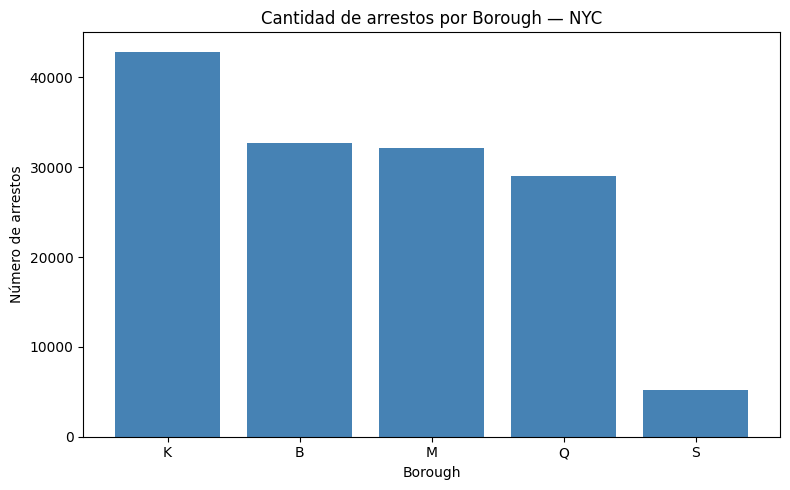

In [10]:
import matplotlib.pyplot as plt

arrestos_boro = df_arrests.groupBy("ARREST_BORO").count().orderBy(F.desc("count")).toPandas()
print(arrestos_boro)

plt.figure(figsize=(8,5))
plt.bar(arrestos_boro["ARREST_BORO"], arrestos_boro["count"], color="steelblue")
plt.title("Cantidad de arrestos por Borough — NYC")
plt.xlabel("Borough")
plt.ylabel("Número de arrestos")
plt.tight_layout()
plt.savefig("fig_arrestos_borough.png", dpi=150)
plt.show()

**Interpretación.** Brooklyn registró la mayor cantidad de arrestos (42.877), seguido por Bronx (32.682) y Manhattan (32.089). Staten Island registró el menor volumen (5.169). Los conteos reflejan el volumen de registros por condado durante el semestre.

---
## Elemento 4 — Distribución de arrestos por nivel de gravedad de la ofensa (LAW_CAT_CD)

  LAW_CAT_CD  count
0          M  82929
1          F  55651
2          V   1896
3        NaN    864
4          9    426
5          I     99
6     (null)      5


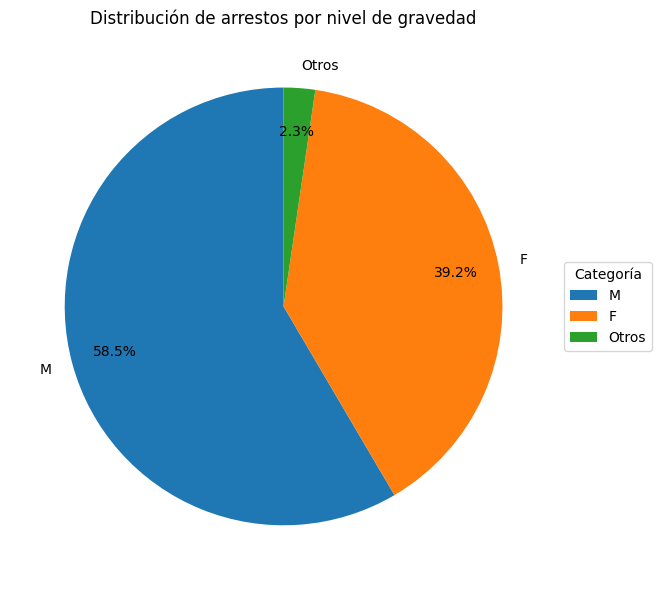

In [11]:
gravedad = df_arrests.groupBy("LAW_CAT_CD").count().orderBy(F.desc("count")).toPandas()
print(gravedad)

# Agrupar categorías minoritarias (<2%) en "Otros" para evitar etiquetas superpuestas
total = gravedad["count"].sum()
gravedad["pct"] = gravedad["count"] / total * 100
principales = gravedad[gravedad["pct"] >= 2].copy()
otros_total = gravedad[gravedad["pct"] < 2]["count"].sum()

if otros_total > 0:
    fila_otros = pd.DataFrame([{"LAW_CAT_CD": "Otros", "count": otros_total}])
    gravedad_agrupada = pd.concat([principales[["LAW_CAT_CD", "count"]], fila_otros], ignore_index=True)
else:
    gravedad_agrupada = principales[["LAW_CAT_CD", "count"]]

plt.figure(figsize=(8,6))
wedges, texts, autotexts = plt.pie(
    gravedad_agrupada["count"],
    labels=gravedad_agrupada["LAW_CAT_CD"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.8
)
plt.title("Distribución de arrestos por nivel de gravedad")
plt.legend(wedges, gravedad_agrupada["LAW_CAT_CD"], title="Categoría", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig("fig_gravedad_ofensa.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación.** Los delitos menores (M) representan el 58,5 % de los arrestos y las felonías (F) el 39,2 %. Las violaciones (V) corresponden al 1,3 %. La gráfica agrupa esta última categoría y los códigos restantes en «Otros».

---
## Elemento 5 — Serie temporal: arrestos por mes

       mes  count
0  2026-01  23542
1  2026-02  21069
2  2026-03  24696
3  2026-04  25129
4  2026-05  25128
5  2026-06  22306


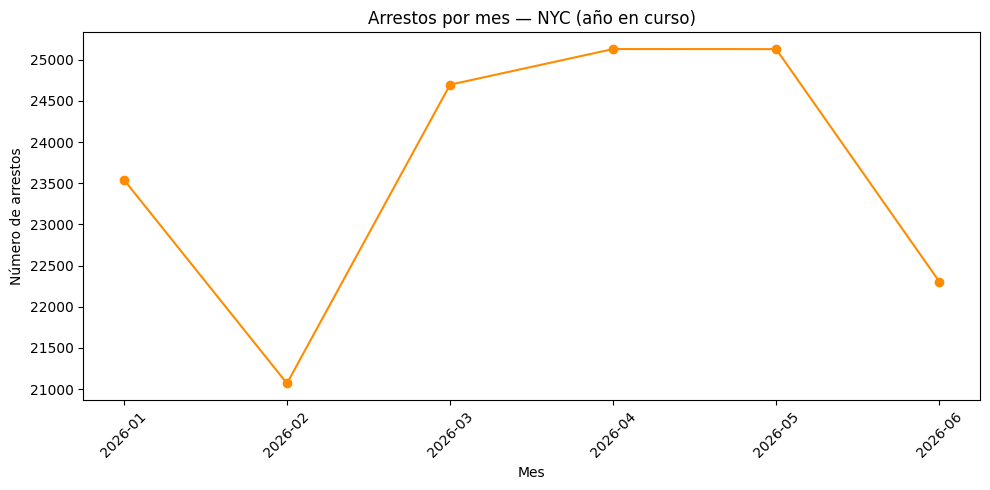

In [12]:
from pyspark.sql.functions import to_date, date_format

df_arrests_fecha = df_arrests.withColumn("ARREST_DATE_PARSED", to_date("ARREST_DATE", "MM/dd/yyyy"))
arrestos_mes = (
    df_arrests_fecha
    .withColumn("mes", date_format("ARREST_DATE_PARSED", "yyyy-MM"))
    .groupBy("mes")
    .count()
    .orderBy("mes")
    .toPandas()
)
print(arrestos_mes)

plt.figure(figsize=(10,5))
plt.plot(arrestos_mes["mes"], arrestos_mes["count"], marker="o", color="darkorange")
plt.title("Arrestos por mes — NYC (año en curso)")
plt.xlabel("Mes")
plt.ylabel("Número de arrestos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("fig_arrestos_mes.png", dpi=150)
plt.show()

**Interpretación.** Febrero tuvo el menor conteo (21.069), seguido por un aumento en marzo y un máximo en abril (25.129). Mayo quedó prácticamente al mismo nivel (25.128) y junio bajó a 22.306. La serie cubre seis meses, un periodo insuficiente para evaluar estacionalidad anual.

---
## Elemento 6 — Histograma de grupo etario de los imputados (AGE_GROUP)

  AGE_GROUP  count
0     25-44  81521
1     45-64  30611
2     18-24  20946
3       <18   5587
4       65+   3205


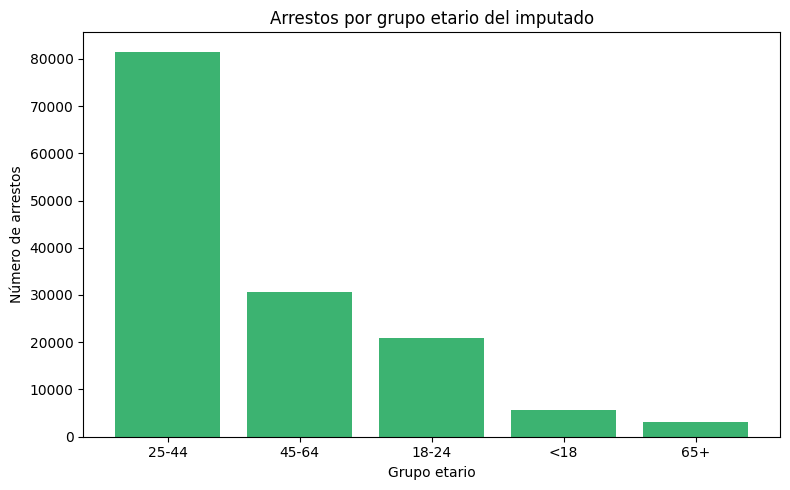

In [13]:
edad = df_arrests.groupBy("AGE_GROUP").count().orderBy(F.desc("count")).toPandas()
print(edad)

plt.figure(figsize=(8,5))
plt.bar(edad["AGE_GROUP"], edad["count"], color="mediumseagreen")
plt.title("Arrestos por grupo etario del imputado")
plt.xlabel("Grupo etario")
plt.ylabel("Número de arrestos")
plt.tight_layout()
plt.savefig("fig_edad.png", dpi=150)
plt.show()

**Interpretación.** El grupo de 25 a 44 años concentra 81.521 arrestos, alrededor del 57,5 % del total. Le sigue el grupo de 45 a 64 años con 30.611 registros. Se cuentan arrestos registrados, por lo que una persona podría aparecer más de una vez.

---
## Elemento 7 — Top 10 precincts con más arrestos (tabla + gráfica horizontal)

   ARREST_PRECINCT  count
0               75   5341
1               14   4382
2               40   4061
3               46   3951
4               44   3882
5              103   3837
6               73   3524
7               52   3409
8               47   3084
9              110   3001


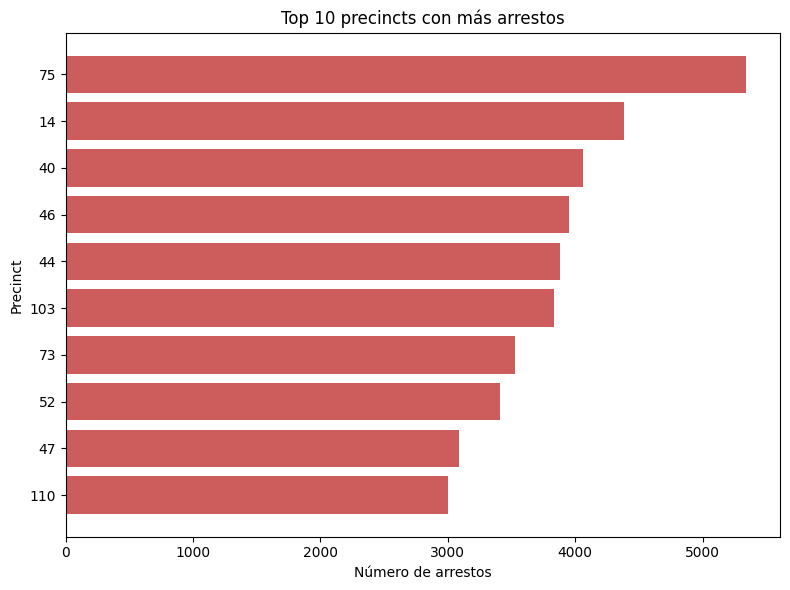

In [14]:
top_precincts = (
    df_arrests.groupBy("ARREST_PRECINCT")
    .count()
    .orderBy(F.desc("count"))
    .limit(10)
    .toPandas()
)
print(top_precincts)

plt.figure(figsize=(8,6))
plt.barh(top_precincts["ARREST_PRECINCT"].astype(str), top_precincts["count"], color="indianred")
plt.gca().invert_yaxis()
plt.title("Top 10 precincts con más arrestos")
plt.xlabel("Número de arrestos")
plt.ylabel("Precinct")
plt.tight_layout()
plt.savefig("fig_top_precincts.png", dpi=150)
plt.show()

**Interpretación.** El precinto 75 (Brooklyn) encabeza el listado con 5.341 arrestos. Le siguen el 14 (Manhattan), con 4.382, y el 40 (Bronx), con 4.061. El orden refleja conteos absolutos durante el semestre.

---
## Elemento 9 (bono/cruce entre datasets) — Pobreza vs. Arrestos por Borough

Cruce simple entre la tasa de pobreza (NYCgov_Pov_Stat, donde 1 = en situación de pobreza) y la cantidad de arrestos, agregados por condado (Boro).

**Nota importante:** el campo `Boro` en el dataset de pobreza usa códigos numéricos (1=Bronx, 2=Brooklyn, 3=Manhattan, 4=Queens, 5=Staten Island, según el diccionario de datos oficial del ACS/PUMS) mientras que `ARREST_BORO` usa letras (B, K, M, Q, S). Hay que homologar antes de cruzar.

  Boro_letra  tasa_pobreza_pct  arrestos
0          B             25.79     32682
1          M             13.83     32089
2          S             13.83      5169
3          Q             15.84     29053
4          K             18.26     42877


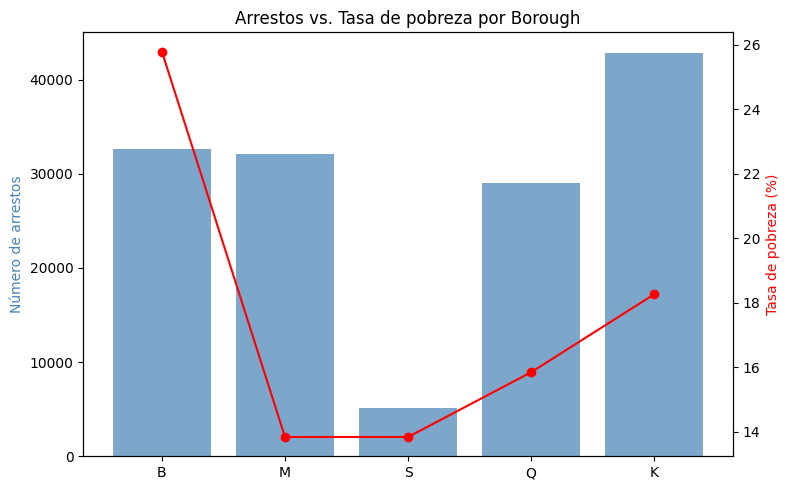

In [15]:
# Mapeo de códigos de Boro (pobreza) a letras (arrestos) para poder comparar
mapeo_boro = {1: "B", 2: "K", 3: "M", 4: "Q", 5: "S"}

pobreza_boro = (
    df_poverty.groupBy("Boro")
    .agg(
        F.count("*").alias("total_personas"),
        F.sum(F.when(F.col("NYCgov_Pov_Stat") == 1, 1).otherwise(0)).alias("en_pobreza")
    )
    .toPandas()
)
pobreza_boro["Boro_letra"] = pobreza_boro["Boro"].map(mapeo_boro)
pobreza_boro["tasa_pobreza_pct"] = (pobreza_boro["en_pobreza"] / pobreza_boro["total_personas"] * 100).round(2)

cruce = pobreza_boro.merge(arrestos_boro, left_on="Boro_letra", right_on="ARREST_BORO")
cruce = cruce.rename(columns={"count": "arrestos"})
print(cruce[["Boro_letra", "tasa_pobreza_pct", "arrestos"]])

fig, ax1 = plt.subplots(figsize=(8,5))
ax1.bar(cruce["Boro_letra"], cruce["arrestos"], color="steelblue", alpha=0.7, label="Arrestos")
ax1.set_ylabel("Número de arrestos", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(cruce["Boro_letra"], cruce["tasa_pobreza_pct"], color="red", marker="o", label="Tasa de pobreza (%)")
ax2.set_ylabel("Tasa de pobreza (%)", color="red")
plt.title("Arrestos vs. Tasa de pobreza por Borough")
plt.tight_layout()
plt.savefig("fig_pobreza_vs_arrestos.png", dpi=150)
plt.show()

**Interpretación.** Bronx presenta la mayor proporción de pobreza de la muestra (25,79 %), mientras que Brooklyn registra el mayor volumen de arrestos (42.877). Es un cruce exploratorio de cinco condados entre la encuesta de 2018 y arrestos de 2026. Para la pregunta 2 se usan pesos muestrales y se acota el análisis a delitos menores.

---
## Fase III (CRISP-DM) — Numeral 1: Filtros y Transformaciones Finales
### 1.1 Filtros de registros inconsistentes, duplicados o alterados

Se aplican cuatro reglas de filtrado distribuidas sobre los DataFrames de Spark:
1. **Integridad de llave primaria y conteos no negativos en Colisiones:** Se descartan filas con `COLLISION_ID` nulo/vacío o con conteos de víctimas (`NUMBER OF ...`) negativos o corruptos por desplazamiento de columnas.
2. **Coherencia aritmética de subcategorías viales:** Se exige que la suma de peatones, ciclistas y motoristas heridos (o fallecidos) no supere el total general `NUMBER OF PERSONS INJURED` (o `KILLED`), eliminando registros alterados (como el outlier de 3,291,249 ciclistas heridos detectado en el EDA).
3. **Unicidad de eventos (`dropDuplicates`):** Eliminación de duplicados por `COLLISION_ID` en colisiones y por `ARREST_KEY` en arrestos.
4. **Validez de factores de expansión muestral (`PWGTP > 0`):** Exclusión de registros sin peso muestral positivo en la encuesta de pobreza.

In [16]:
from pyspark.sql import functions as F

# ---------- COLLISIONS ----------
n_antes = df_col_raw.count()

num_cols = [c for c in df_col_raw.columns if c.startswith("NUMBER OF")]
col = df_col_raw
for c in num_cols:
    col = col.withColumn(c, F.expr(f"try_cast(`{c}` AS INT)"))
col = col.withColumn("COLLISION_ID", F.trim(F.col("COLLISION_ID")))

# El identificador puede ser alfanumérico. Solo los conteos se convierten a entero.
cond_validas = F.col("COLLISION_ID").isNotNull() & (F.length("COLLISION_ID") > 0)
for c in num_cols:
    cond_validas = cond_validas & (F.col(c) >= 0)

col = (col.filter(cond_validas)
    .filter(
        (F.col("NUMBER OF PEDESTRIANS INJURED") + F.col("NUMBER OF CYCLIST INJURED")
         + F.col("NUMBER OF MOTORIST INJURED")) <= F.col("NUMBER OF PERSONS INJURED"))
    .filter(
        (F.col("NUMBER OF PEDESTRIANS KILLED") + F.col("NUMBER OF CYCLIST KILLED")
         + F.col("NUMBER OF MOTORIST KILLED")) <= F.col("NUMBER OF PERSONS KILLED"))
    .dropDuplicates(["COLLISION_ID"])
    # Los CSV usan coma decimal ("40,62179"): se reemplaza antes de convertir
    .withColumn("lat", F.expr("try_cast(replace(LATITUDE, ',', '.') AS DOUBLE)"))
    .withColumn("lon", F.expr("try_cast(replace(LONGITUDE, ',', '.') AS DOUBLE)"))
    .withColumn("coord_valida",
        F.coalesce(F.col("lat").between(40.49, 40.92)
                   & F.col("lon").between(-74.27, -73.68), F.lit(False))))

n_despues = col.count()
print(f"Colisiones: {n_antes} -> {n_despues} (descartadas: {n_antes - n_despues})")

# ---------- ARRESTS ----------
arr = (df_arrests
    .filter(F.col("ARREST_KEY").isNotNull())
    .dropDuplicates(["ARREST_KEY"])
    .withColumn("gravedad_reportada", F.col("LAW_CAT_CD"))
    .withColumn("LAW_CAT_CD",
        F.when(F.col("LAW_CAT_CD").isin("F", "M", "V"), F.col("LAW_CAT_CD")))
    .withColumn("AGE_GROUP",
        F.when(F.col("AGE_GROUP").isin("<18", "18-24", "25-44", "45-64", "65+"),
               F.col("AGE_GROUP")).otherwise("DESCONOCIDO"))
    .withColumn("coord_valida",
        F.col("X_COORD_CD").between(900000, 1070000)
        & F.col("Y_COORD_CD").between(110000, 275000)))

# ---------- POVERTY ----------
pov = df_poverty.filter(F.col("PWGTP") > 0)
# Importes en formato local (punto de miles y coma decimal).
importes = [c for c in pov.columns if c.startswith("EST_") or c.endswith("_adj")]
importes += ["NYCgov_Income", "NYCgov_Threshold", "PreTaxIncome_PU"]
for c in importes:
    if dict(pov.dtypes)[c] == "string":
        pov = pov.withColumn(
            c, F.expr(f"try_cast(replace(replace(`{c}`, '.', ''), ',', '.') AS DOUBLE)"))

Colisiones: 2305623 -> 2305355 (descartadas: 268)


### 1.2 Transformaciones: estandarización de tipos, fechas, texto y coordenadas

In [17]:
# ---------- ARRESTS ----------
arr = (arr
    .withColumn("fecha", F.to_date("ARREST_DATE", "MM/dd/yyyy"))
    .withColumn("Latitude",  F.expr("try_cast(replace(Latitude, ',', '.') AS DOUBLE)"))
    .withColumn("Longitude", F.expr("try_cast(replace(Longitude, ',', '.') AS DOUBLE)")))

for c in ["OFNS_DESC", "PD_DESC", "PERP_SEX", "PERP_RACE"]:
    arr = arr.withColumn(c, F.upper(F.trim(F.col(c))))

# ---------- COLLISIONS ----------
arr_dep, col_dep, pov_dep = arr, col, pov

col = (col
    .withColumn("fecha", F.to_date("CRASH DATE", "MM/dd/yyyy"))
    .withColumn("hora", F.hour(F.to_timestamp("CRASH TIME", "H:mm"))))

for c in ["BOROUGH", "ON STREET NAME", "CROSS STREET NAME",
          "VEHICLE TYPE CODE 1", "VEHICLE TYPE CODE 2",
          "CONTRIBUTING FACTOR VEHICLE 1", "CONTRIBUTING FACTOR VEHICLE 2"]:
    col = col.withColumn(c, F.upper(F.trim(F.col(f"`{c}`"))))

## Filtros y transformaciones finales

1. **Datos de origen.** Los DataFrames de lectura conservan los datos recibidos y permiten revisar esquema, frecuencias, descriptivos y nulos.
2. **Datos depurados.** Se filtran colisiones con llave ausente o conteos negativos, no numéricos o incompatibles con el total. Se eliminan llaves duplicadas y se excluyen pesos muestrales no positivos. Estas reglas protegen los conteos de eventos y los denominadores de la encuesta.
3. **Datos para análisis.** Se convierten fechas y conteos a tipos adecuados, se normalizan texto y separadores decimales, se homologan condados y se calculan tasas por población. Se conserva la gravedad reportada antes de imputarla, para poder analizar delitos menores y felonías según la clasificación original.

El indicador de coordenadas permite excluir puntos inválidos de los análisis espaciales y conservar esos registros en los análisis que prescinden de ubicación exacta. Las variables para los modelos se construyen más adelante sobre esta capa.

### Conteos antes y después de los filtros

In [18]:
# Registros antes y después de aplicar los filtros (los valores salen de la ejecución)
n_arr_antes = df_arrests.count();  n_arr_desp = arr.count()
n_pov_antes = df_poverty.count();  n_pov_desp = pov.count()
n_col_antes = df_col_raw.count();  n_col_desp = col.count()

resumen_filtros = pd.DataFrame({
    "dataset":   ["Arrestos", "Colisiones", "Pobreza"],
    "antes":     [n_arr_antes, n_col_antes, n_pov_antes],
    "despues":   [n_arr_desp,  n_col_desp,  n_pov_desp],
})
resumen_filtros["descartados"] = resumen_filtros["antes"] - resumen_filtros["despues"]
print(resumen_filtros)

# Indicadores de calidad creados (no eliminan filas)
print("\nArrestos por validez de coordenadas planas:")
arr.groupBy("coord_valida").count().show()
print("Colisiones por validez de coordenadas geográficas:")
col.groupBy("coord_valida").count().show()

      dataset    antes  despues  descartados
0    Arrestos   141870   141870            0
1  Colisiones  2305623  2305355          268
2     Pobreza    68273    68273            0

Arrestos por validez de coordenadas planas:
+------------+------+
|coord_valida| count|
+------------+------+
|        true|141861|
|       false|     9|
+------------+------+

Colisiones por validez de coordenadas geográficas:
+------------+-------+
|coord_valida|  count|
+------------+-------+
|        true|2056013|
|       false| 249342|
+------------+-------+



### Limpieza: imputación de `LAW_CAT_CD` por moda

In [19]:
from pyspark.sql.window import Window

# Moda de LAW_CAT_CD por código de delito (PD_CD); si no existe, moda global
moda_pd = (arr.filter(F.col("LAW_CAT_CD").isNotNull())
    .groupBy("PD_CD", "LAW_CAT_CD").count()
    .withColumn("rn", F.row_number().over(
        Window.partitionBy("PD_CD").orderBy(F.desc("count"), "LAW_CAT_CD")))
    .filter("rn = 1")
    .select("PD_CD", F.col("LAW_CAT_CD").alias("moda_pd")))

moda_global = (arr.filter(F.col("LAW_CAT_CD").isNotNull())
    .groupBy("LAW_CAT_CD").count().orderBy(F.desc("count"), "LAW_CAT_CD").first()[0])

nulos_antes = arr.filter(F.col("LAW_CAT_CD").isNull()).count()

arr = (arr.join(moda_pd, "PD_CD", "left")
    .withColumn("LAW_CAT_CD", F.coalesce("LAW_CAT_CD", "moda_pd", F.lit(moda_global)))
    .drop("moda_pd"))

nulos_despues = arr.filter(F.col("LAW_CAT_CD").isNull()).count()
print("Moda global de LAW_CAT_CD:", moda_global)
print("Nulos en LAW_CAT_CD -> antes:", nulos_antes, "| después:", nulos_despues)

Moda global de LAW_CAT_CD: M
Nulos en LAW_CAT_CD -> antes: 1394 | después: 0


### Limpieza: nulos estructurales (categoría constante / código "no aplica")

In [20]:
# Marca los campos 3 a 5 sin dato. El indicador distingue columnas sin reporte.
for i in [3, 4, 5]:
    col = col.fillna({f"VEHICLE TYPE CODE {i}": f"SIN_VEHICULO_{i}",
                      f"CONTRIBUTING FACTOR VEHICLE {i}": f"SIN_VEHICULO_{i}"})

# Pobreza: nulos por salto lógico de la encuesta -> código -1 ("no aplica")
pov = pov.fillna(-1, subset=["ENG", "JWTR", "WKW", "ESR", "MSP", "LANX"])

# Verificación: nulos restantes en las columnas tratadas
col.select([F.count(F.when(F.col(f"`{c}`").isNull(), c)).alias(c) for c in
            ["VEHICLE TYPE CODE 3", "VEHICLE TYPE CODE 4", "VEHICLE TYPE CODE 5"]]).show()
pov.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in
            ["ENG", "JWTR", "WKW", "ESR", "MSP", "LANX"]]).show()

# Estas referencias mantienen disponibles las etapas de cada fuente.
arr_analisis, col_analisis, pov_analisis = arr, col.cache(), pov
print("Tipos utilizados en el análisis:")
arr_analisis.select("fecha", "Latitude", "Longitude", "gravedad_reportada").printSchema()
col_analisis.select("fecha", "hora", "lat", "lon", "NUMBER OF PERSONS KILLED").printSchema()
pov_analisis.select("PWGTP", "ESR", "SCHL", "NYCgov_Income").printSchema()

+-------------------+-------------------+-------------------+
|VEHICLE TYPE CODE 3|VEHICLE TYPE CODE 4|VEHICLE TYPE CODE 5|
+-------------------+-------------------+-------------------+
|                  0|                  0|                  0|
+-------------------+-------------------+-------------------+

+---+----+---+---+---+----+
|ENG|JWTR|WKW|ESR|MSP|LANX|
+---+----+---+---+---+----+
|  0|   0|  0|  0|  0|   0|
+---+----+---+---+---+----+

Tipos utilizados en el análisis:
root
 |-- fecha: date (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- gravedad_reportada: string (nullable = true)

root
 |-- fecha: date (nullable = true)
 |-- hora: integer (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- NUMBER OF PERSONS KILLED: integer (nullable = true)

root
 |-- PWGTP: double (nullable = true)
 |-- ESR: integer (nullable = true)
 |-- SCHL: integer (nullable = true)
 |-- NYCgov_Income: dou

### Transformación: estandarización por población (tasas por 100,000 habitantes)

La población por condado se estima sumando el peso muestral `PWGTP` del dataset de pobreza. Con ella se normalizan los arrestos y las colisiones para poder comparar condados de tamaños muy distintos.

**Consideraciones:**
- Las colisiones se cuentan solo en filas que ya tienen `BOROUGH`, por lo que las tasas excluyen eventos cuyo condado se desconoce.
- La población proviene de 2018, los arrestos corresponden al año en curso (acumulado) y las colisiones se toman de un único año de referencia. Las tasas sirven para comparar condados entre sí, no como valores absolutos.

In [21]:
# Homologación de códigos de condado entre los tres datasets
mapa_pov = {1: "BRONX", 2: "BROOKLYN", 3: "MANHATTAN", 4: "QUEENS", 5: "STATEN ISLAND"}
mapa_arr = {"B": "BRONX", "K": "BROOKLYN", "M": "MANHATTAN",
            "Q": "QUEENS", "S": "STATEN ISLAND"}

# Población estimada por condado (suma de PWGTP)
poblacion = pov.groupBy("Boro").agg(F.sum("PWGTP").alias("poblacion")).toPandas()
poblacion["BORO"] = poblacion["Boro"].astype(int).map(mapa_pov)

# Arrestos por condado
arr_boro = (arr.groupBy("ARREST_BORO").count().toPandas()
    .assign(BORO=lambda d: d["ARREST_BORO"].map(mapa_arr))
    .rename(columns={"count": "arrestos"}))

# Colisiones por condado en el último año completo disponible
anio_ref = col.agg(F.max("fecha")).first()[0].year - 1
print("Año de referencia para colisiones:", anio_ref)
col_boro = (col.filter((F.year("fecha") == anio_ref) & F.col("BOROUGH").isNotNull())
    .groupBy("BOROUGH").count().toPandas()
    .rename(columns={"BOROUGH": "BORO", "count": "colisiones"}))

tasas = (poblacion[["BORO", "poblacion"]]
    .merge(arr_boro[["BORO", "arrestos"]], on="BORO")
    .merge(col_boro, on="BORO"))
tasas["arrestos_x100k"]   = (tasas["arrestos"]   / tasas["poblacion"] * 1e5).round(1)
tasas["colisiones_x100k"] = (tasas["colisiones"] / tasas["poblacion"] * 1e5).round(1)
print(tasas)

Año de referencia para colisiones: 2025


            BORO    poblacion  arrestos  colisiones  arrestos_x100k  \
0          BRONX  1388068.178     32682       12291          2354.5   
1      MANHATTAN  1554658.643     32089       14488          2064.1   
2  STATEN ISLAND   469393.000      5169        3128          1101.2   
3         QUEENS  2250749.000     29053       21840          1290.8   
4       BROOKLYN  2540638.000     42877       26712          1687.6   

   colisiones_x100k  
0             885.5  
1             931.9  
2             666.4  
3             970.3  
4            1051.4  


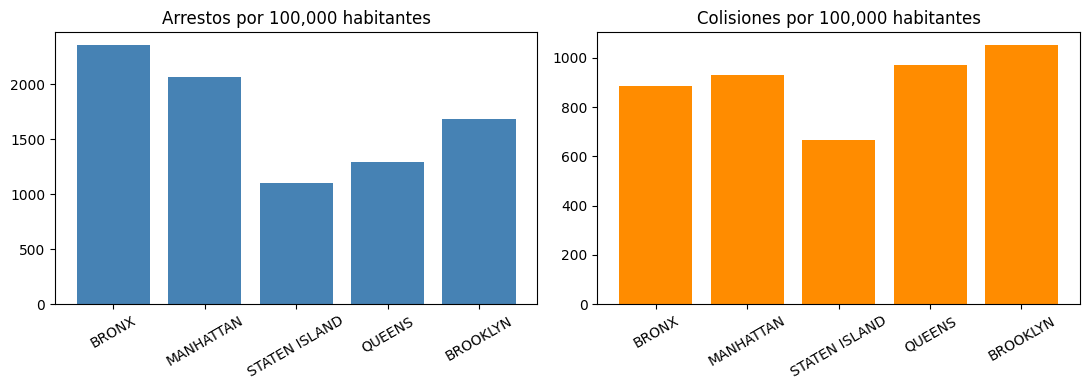

In [22]:
# Gráfica comparativa de tasas por 100,000 habitantes
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(tasas["BORO"], tasas["arrestos_x100k"], color="steelblue")
axes[0].set_title("Arrestos por 100,000 habitantes")
axes[1].bar(tasas["BORO"], tasas["colisiones_x100k"], color="darkorange")
axes[1].set_title("Colisiones por 100,000 habitantes")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("fig_tasas_por_100k.png", dpi=150)
plt.show()

**Interpretación.** Brooklyn lidera el volumen de arrestos, pero Bronx pasa al primer lugar al dividir por la población estimada. En colisiones de 2025, Brooklyn conserva el primer lugar tanto por conteo (26.712) como por tasa (1.051,4 por 100.000 habitantes). Las dos series cubren periodos distintos y la tasa de colisiones usa los eventos con condado informado.

### Elemento 8 — Heridos y fallecidos en las colisiones depuradas

                        Total
Personas heridas       779372
Personas fallecidas      3746
Peatones heridos       141625
Peatones fallecidos      1847
Ciclistas heridos       68866
Ciclistas fallecidos      273
Motoristas heridos     552978
Motoristas fallecidos    1484


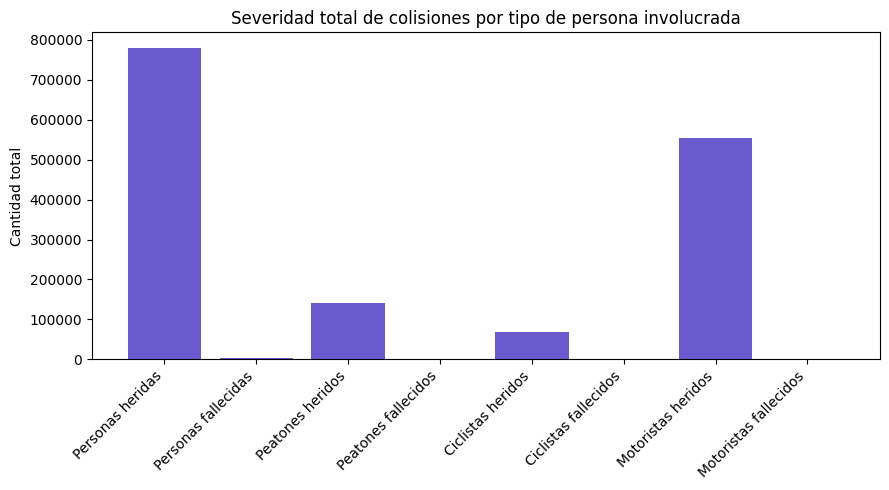

In [23]:
def suma_lesiones(col_name):
    return F.sum(col_name)

severidad = col_analisis.select(
    suma_lesiones("NUMBER OF PERSONS INJURED").alias("Personas heridas"),
    suma_lesiones("NUMBER OF PERSONS KILLED").alias("Personas fallecidas"),
    suma_lesiones("NUMBER OF PEDESTRIANS INJURED").alias("Peatones heridos"),
    suma_lesiones("NUMBER OF PEDESTRIANS KILLED").alias("Peatones fallecidos"),
    suma_lesiones("NUMBER OF CYCLIST INJURED").alias("Ciclistas heridos"),
    suma_lesiones("NUMBER OF CYCLIST KILLED").alias("Ciclistas fallecidos"),
    suma_lesiones("NUMBER OF MOTORIST INJURED").alias("Motoristas heridos"),
    suma_lesiones("NUMBER OF MOTORIST KILLED").alias("Motoristas fallecidos"),
).toPandas().T
severidad.columns = ["Total"]
print(severidad)

plt.figure(figsize=(9,5))
plt.bar(severidad.index, severidad["Total"], color="slateblue")
plt.title("Severidad total de colisiones por tipo de persona involucrada")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Cantidad total")
plt.tight_layout()
plt.savefig("fig_severidad_colisiones.png", dpi=150)
plt.show()

**Interpretación.** En el histórico limpio hay 779.372 personas heridas y 3.746 fallecidas. Los motoristas concentran el mayor conteo de heridos (552.978) y los peatones el mayor conteo de fallecidos (1.847). Para elaborar la gráfica se descartaron registros con conteos incoherentes y duplicados.

---
## Numeral 2 — Respuestas a las Preguntas de Negocio Planteadas

### 1. Concentración espacial y temporal de los arrestos por delitos graves (felonías) en los condados de Nueva York

**Alcance técnico y punto de contacto con el negocio (Objetivo 1 — NYPD):** El atributo `ARREST_DATE` del conjunto *NYPD Arrest Data* se publica con granularidad diaria (`MM/dd/yyyy`, sin marca de hora). Por ello, para responder al objetivo de negocio de planificación dinámica de patrullas del NYPD, se analiza la concentración espacial de los arrestos por delitos graves (`gravedad_reportada == 'F'`, felonías) a lo largo del ciclo semanal (lunes a domingo) en los cinco condados durante el primer semestre de 2026 (`2026-01-01` a `2026-06-30`), comparando tanto el volumen absoluto como la proporción intrasemanal dentro de cada condado.

Conteo de arrestos por delitos graves (Felonías - F) según día y condado:


BORO        BRONX  BROOKLYN  MANHATTAN  QUEENS  STATEN ISLAND  TOTAL_NYC
dia_semana                                                              
Lunes        1528      2132       1282    1401            253       6596
Martes       2440      3024       2059    2004            354       9881
Miércoles    2431      3101       2145    2161            352      10190
Jueves       2068      2861       2213    1959            368       9469
Viernes      1751      2414       1884    1587            334       7970
Sábado       1388      1860       1377    1205            183       6013
Domingo      1337      1705       1145    1156            189       5532

               Total felonías   Día pico  Arrestos día pico  Mar-Jue (%)  Fin de semana (%)
BORO                                                                                       
BRONX                   12943     Martes               2440        53.61              21.05
BROOKLYN                17097  Miércoles               3101        52.56              20.85
MANHATTAN               12105     Jueves               2213        53.01              20.84
QUEENS                  11473  Miércoles               2161        53.38              20.58
STATEN ISLAND            2033     Jueves                368        52.82              18.30

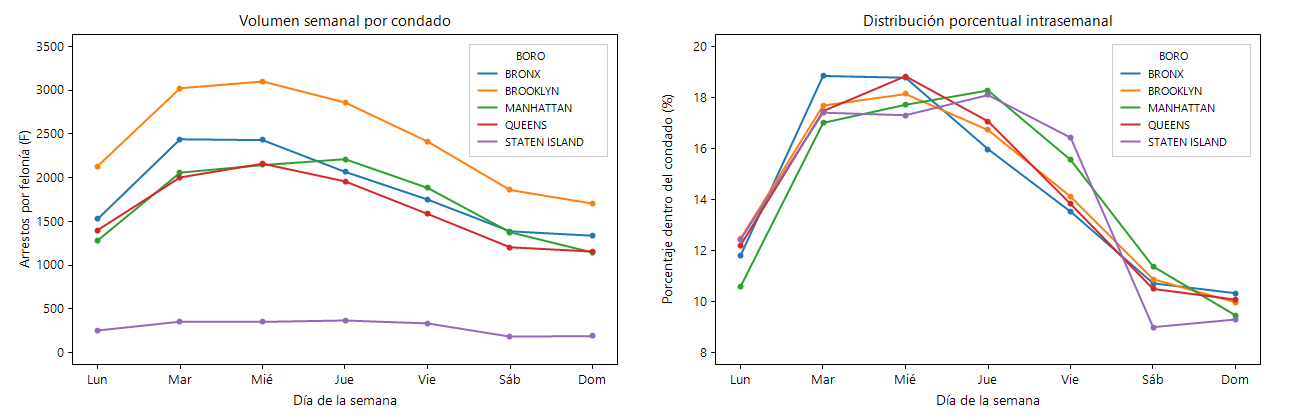

In [24]:
from IPython.display import display

inicio, fin = "2026-01-01", "2026-06-30"
arr_sem = arr_analisis.filter(F.col("fecha").between(inicio, fin))
col_sem = (col_analisis.filter(F.col("fecha").between(inicio, fin))
    .withColumn("fatal", (F.col("NUMBER OF PERSONS KILLED") > 0).cast("int")))
pov_base = pov_analisis.withColumn("BORO", F.create_map(
    *[F.lit(v) for pareja in mapa_pov.items() for v in pareja])[F.col("Boro")])

def barras(tabla, x, columnas, titulo, etiqueta, horizontal=False):
    ax = tabla.set_index(x)[columnas].plot.barh(figsize=(10, 5)) if horizontal else (
        tabla.set_index(x)[columnas].plot.bar(figsize=(10, 5), rot=25))
    ax.set(title=titulo)
    if horizontal:
        ax.set(xlabel=etiqueta, ylabel="")
        ax.invert_yaxis()
    else:
        ax.set(xlabel="", ylabel=etiqueta)
    plt.tight_layout()
    plt.show()

# --- Pregunta 1: Felonías (F) por día de la semana y condado ---
dias_orden = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
# En Spark dayofweek: 1=Domingo, 2=Lunes, ..., 7=Sábado
mapa_dia_spark = {2: "Lunes", 3: "Martes", 4: "Miércoles", 5: "Jueves",
                  6: "Viernes", 7: "Sábado", 1: "Domingo"}

q1_raw = (arr_sem.filter(F.col("gravedad_reportada") == "F")
    .withColumn("BORO", F.create_map(*[F.lit(v) for p in mapa_arr.items() for v in p])[F.col("ARREST_BORO")])
    .withColumn("dia_semana", F.create_map(*[F.lit(v) for p in mapa_dia_spark.items() for v in p])[F.dayofweek("fecha")])
    .groupBy("dia_semana", "BORO").count().toPandas())

tabla_q1 = (q1_raw.pivot(index="dia_semana", columns="BORO", values="count")
    .reindex(index=dias_orden, columns=["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"])
    .fillna(0).astype(int))
prop_q1 = (tabla_q1.div(tabla_q1.sum(axis=0), axis=1) * 100).round(2)
tabla_q1["TOTAL_NYC"] = tabla_q1.sum(axis=1)

print("Conteo de arrestos por delitos graves (Felonías - F) según día y condado:")
display(tabla_q1)

resumen_q1 = pd.DataFrame({
    "Total felonías": tabla_q1.drop(columns="TOTAL_NYC").sum(axis=0),
    "Día pico": tabla_q1.drop(columns="TOTAL_NYC").idxmax(axis=0),
    "Arrestos día pico": tabla_q1.drop(columns="TOTAL_NYC").max(axis=0),
    "Mar-Jue (%)": prop_q1.loc[["Martes", "Miércoles", "Jueves"]].sum(axis=0).round(2),
    "Fin de semana (%)": prop_q1.loc[["Sábado", "Domingo"]].sum(axis=0).round(2),
})
display(resumen_q1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
tabla_q1.drop(columns="TOTAL_NYC").plot(ax=axes[0], marker="o", title="Volumen semanal por condado",
                                         ylabel="Arrestos por felonía (F)", xlabel="Día de la semana")
prop_q1.plot(ax=axes[1], marker="o", title="Distribución porcentual intrasemanal",
             ylabel="Porcentaje dentro del condado (%)", xlabel="Día de la semana")
plt.tight_layout()
plt.savefig("fig_q1_felonias_dia_boro.png", dpi=150)
plt.show()

**Interpretación (Pregunta 1).** En el primer semestre de 2026 se registraron 55.651 arrestos por felonías (`F`). Brooklyn concentra el mayor volumen absoluto (17.097), seguido por Bronx (12.943), Manhattan (12.105), Queens (11.473) y Staten Island (2.033). En los cinco condados se observa un marcado ciclo intrasemanal: más de la mitad de las detenciones por delitos graves (entre el 52,56 % y el 53,61 %) se concentran en la franja de **martes a jueves** (29.540 arrestos acumulados), mientras que el fin de semana (sábado y domingo) reúne apenas entre el 18,30 % y el 21,05 %. Además, el día pico se desplaza territorialmente: Bronx alcanza su máximo los martes (2.440, 18,85 %), Brooklyn y Queens los miércoles (3.101 y 2.161; 18,14 % y 18,84 %), y Manhattan y Staten Island los jueves (2.213 y 368; 18,28 % y 18,10 %). Esto permite al NYPD escalonar el despliegue de unidades tácticas y de cumplimiento de órdenes judiciales según el día pico de cada condado.

---
### 2. Pobreza y arrestos por delitos menores

Se estima la pobreza de 2018 con el peso personal PWGTP. Se comparan las tasas con los conteos de arrestos registrados como M y, como complemento, con los arrestos por 100.000 habitantes estimados. Con cinco condados y periodos distintos, los coeficientes se leen de forma descriptiva.

,BORO,pobreza_pct,arrestos_menores,menores_x100k
0,QUEENS,17.02,16767,744.95
1,BROOKLYN,20.31,24442,962.04
2,BRONX,27.12,19268,1388.12
3,MANHATTAN,15.12,19337,1243.81
4,STATEN ISLAND,16.00,3115,663.62


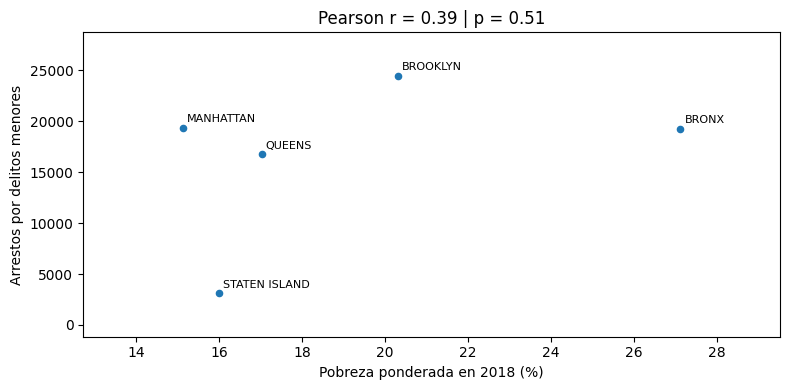

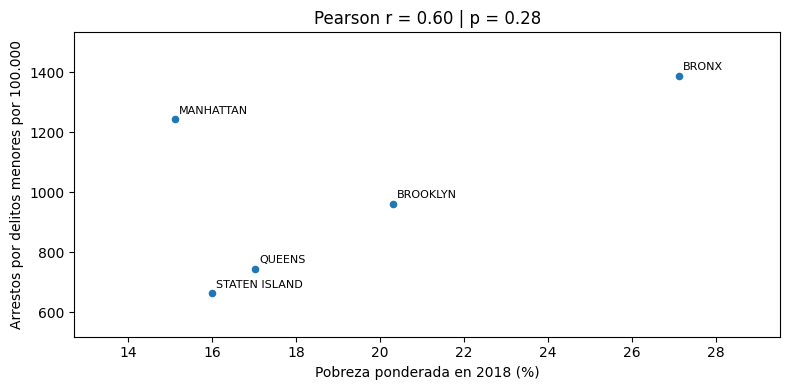

In [25]:
from scipy.stats import pearsonr

pobreza_ponderada = (pov_base.filter(F.col("NYCgov_Pov_Stat").isin(1, 2))
    .groupBy("BORO")
    .agg((100 * F.sum(F.when(F.col("NYCgov_Pov_Stat") == 1, F.col("PWGTP")).otherwise(0))
          / F.sum("PWGTP")).alias("pobreza_pct"))
    .toPandas())
menores = (arr_sem.filter(F.col("gravedad_reportada") == "M")
    .groupBy("ARREST_BORO").count().toPandas()
    .assign(BORO=lambda t: t["ARREST_BORO"].map(mapa_arr))
    .rename(columns={"count": "arrestos_menores"}))
q2 = (pobreza_ponderada.merge(menores[["BORO", "arrestos_menores"]], on="BORO")
      .merge(poblacion[["BORO", "poblacion"]], on="BORO"))
q2["menores_x100k"] = q2["arrestos_menores"] / q2["poblacion"] * 1e5
display(q2.drop(columns="poblacion").round(2))
for variable, etiqueta in [("arrestos_menores", "Arrestos por delitos menores"),
                            ("menores_x100k", "Arrestos por delitos menores por 100.000")]:
    r, p_valor = pearsonr(q2["pobreza_pct"], q2[variable])
    ax = q2.plot.scatter(x="pobreza_pct", y=variable, figsize=(8, 4))
    for fila in q2.itertuples():
        ax.annotate(fila.BORO, (fila.pobreza_pct, getattr(fila, variable)), xytext=(3, 4),
                    textcoords="offset points", fontsize=8)
    ax.set(xlabel="Pobreza ponderada en 2018 (%)", ylabel=etiqueta, title=f"Pearson r = {r:.2f} | p = {p_valor:.2f}")
    ax.margins(.2)
    plt.tight_layout()
    plt.show()

**Interpretación.** La correlación entre pobreza ponderada y el volumen de arrestos por delitos menores fue r = 0,39 (p = 0,51). Al usar arrestos por 100.000 habitantes subió a r = 0,60 (p = 0,28). Con cinco condados, ninguno de los cruces ofrece evidencia suficiente de asociación al nivel del 5 %.

### 3. Factores y tipos de vehículo en colisiones con peatones o ciclistas afectados

Se consideran las colisiones con al menos un peatón o ciclista herido o fallecido. Se revisan los cinco campos de cada familia de categorías. Se cuenta una vez cada combinación de categoría y colisión, aunque aparezca en más de una posición.

,categoria,count
0,DRIVER INATTENTION/DISTRACTION,1686
1,FAILURE TO YIELD RIGHT-OF-WAY,1243
2,PEDESTRIAN/BICYCLIST/OTHER PEDESTRIAN ERROR/CO...,378
3,TRAFFIC CONTROL DISREGARDED,170
4,BACKING UNSAFELY,144
5,UNSAFE SPEED,140
6,PASSING OR LANE USAGE IMPROPER,135
7,TURNING IMPROPERLY,115
8,VIEW OBSTRUCTED/LIMITED,99
9,OTHER VEHICULAR,98


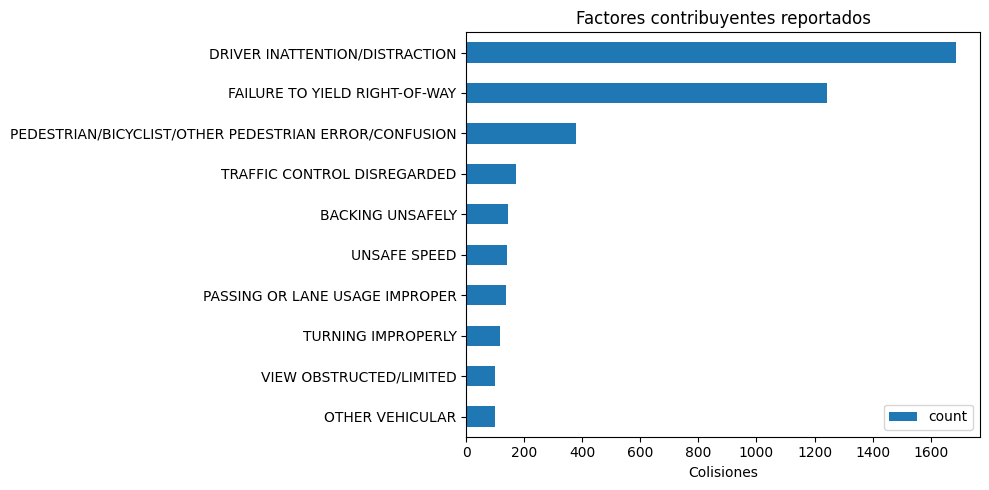

,categoria,count
0,STATION WAGON/SPORT UTILITY VEHICLE,1741
1,SEDAN,1554
2,BICYCLIST,1035
3,BIKE,982
4,4 DR SEDAN,762
5,TAXI,242
6,PICK-UP TRUCK,162
7,VAN,106
8,BUS,83
9,MOPED,74


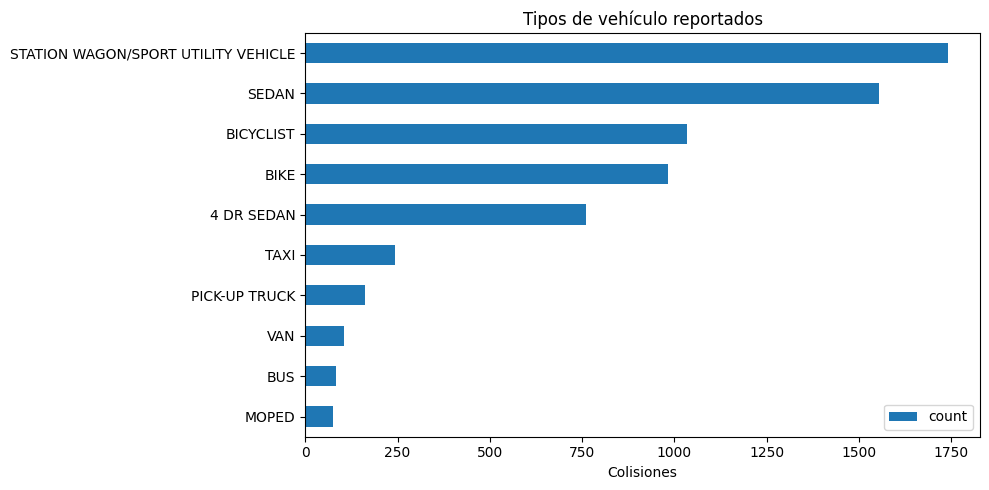

In [26]:
vulnerables = col_sem.filter(
    (F.col("NUMBER OF PEDESTRIANS INJURED") + F.col("NUMBER OF PEDESTRIANS KILLED")
     + F.col("NUMBER OF CYCLIST INJURED") + F.col("NUMBER OF CYCLIST KILLED")) > 0)
for prefijo, titulo in [("CONTRIBUTING FACTOR VEHICLE", "Factores contribuyentes reportados"),
                        ("VEHICLE TYPE CODE", "Tipos de vehículo reportados")]:
    categorias = [F.upper(F.trim(F.col(f"{prefijo} {i}"))) for i in range(1, 6)]
    tabla = (vulnerables.select("COLLISION_ID", F.explode(F.array_distinct(F.array(*categorias))).alias("categoria"))
        .filter(F.col("categoria").isNotNull() & ~F.col("categoria").isin("", "UNSPECIFIED", "UNKNOWN", "DOES NOT APPLY")
                & ~F.col("categoria").startswith("SIN_VEHICULO_"))
        .groupBy("categoria").count().orderBy(F.desc("count"), "categoria").limit(10).toPandas())
    display(tabla)
    barras(tabla, "categoria", ["count"], titulo, "Colisiones", horizontal=True)

**Interpretación.** Entre los factores específicos reportados, la distracción o falta de atención del conductor aparece en 1.686 colisiones y no ceder el paso en 1.243. Las categorías de vehículo más frecuentes son las camionetas familiares/SUV (1.741) y los sedanes (1.554). Las frecuencias cuentan colisiones donde se registró cada categoría.

### 4. Desempleo, educación y siniestralidad vial fatal

Se usa la proporción ponderada de desempleados en la fuerza laboral civil (ESR 3 entre ESR 1, 2 y 3) y se describe la distribución del máximo título alcanzado entre personas de 25 años o más (SCHL). La siniestralidad se aproxima con colisiones con al menos un fallecido por 100.000 habitantes estimados y condado informado. Se comparan condiciones sociales de 2018 y eventos del primer semestre de 2026 en cinco condados.

[NYC Open Data — medición de pobreza de 2018](https://data.cityofnewyork.us/City-Government/NYCgov-Poverty-Measure-Data-2018-/cts7-vksw) · [Diccionario ACS PUMS de 2018](https://www2.census.gov/programs-surveys/acs/tech_docs/pums/data_dict/PUMS_Data_Dictionary_2018.pdf)

,BORO,desempleo_pct,Estudios superiores sin grado universitario,Secundaria completa o equivalente,Sin diploma de secundaria,Universitario o superior,fatales,fatales_x100k
0,QUEENS,5.11,22.29,26.53,17.32,33.87,31,1.38
1,BROOKLYN,4.67,19.09,24.94,16.42,39.55,26,1.02
2,BRONX,9.56,25.15,27.34,26.26,21.25,19,1.37
3,MANHATTAN,4.36,13.35,12.43,11.80,62.41,21,1.35
4,STATEN ISLAND,4.40,23.61,30.91,12.17,33.31,3,0.64


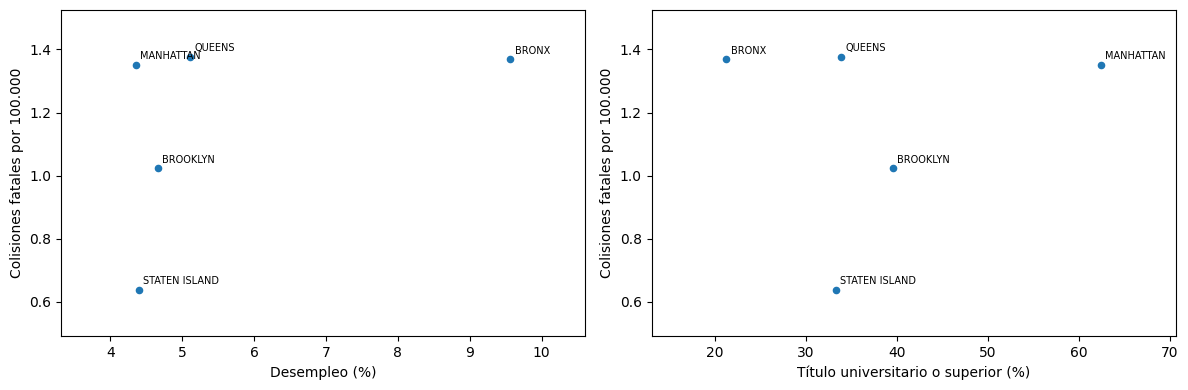

In [27]:
empleo = (pov_base.filter(F.col("ESR").isin(1, 2, 3)).groupBy("BORO")
    .agg((100 * F.sum(F.when(F.col("ESR") == 3, F.col("PWGTP")).otherwise(0))
          / F.sum("PWGTP")).alias("desempleo_pct")).toPandas())
nivel_edu = (F.when(F.col("SCHL") >= 21, "Universitario o superior")
    .when(F.col("SCHL") >= 18, "Estudios superiores sin grado universitario")
    .when(F.col("SCHL") >= 16, "Secundaria completa o equivalente")
    .otherwise("Sin diploma de secundaria"))
educacion = (pov_base.filter((F.col("AGEP") >= 25) & F.col("SCHL").between(1, 24))
    .withColumn("nivel", nivel_edu).groupBy("BORO", "nivel").sum("PWGTP").toPandas()
    .pivot(index="BORO", columns="nivel", values="sum(PWGTP)").fillna(0))
educacion = (educacion.div(educacion.sum(axis=1), axis=0) * 100).reset_index()
siniestralidad = (col_sem.filter(F.col("BOROUGH").isin(*mapa_pov.values()))
    .groupBy(F.col("BOROUGH").alias("BORO")).agg(F.sum("fatal").alias("fatales")).toPandas())
q4 = (empleo.merge(educacion, on="BORO").merge(siniestralidad, on="BORO")
      .merge(poblacion[["BORO", "poblacion"]], on="BORO"))
q4["fatales_x100k"] = q4["fatales"] / q4["poblacion"] * 1e5
display(q4.drop(columns="poblacion").round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, variable, etiqueta in zip(axes, ["desempleo_pct", "Universitario o superior"],
                                ["Desempleo (%)", "Título universitario o superior (%)"]):
    q4.plot.scatter(x=variable, y="fatales_x100k", ax=ax)
    for _, fila in q4.iterrows():
        ax.annotate(fila["BORO"], (fila[variable], fila["fatales_x100k"]), xytext=(3, 4),
                    textcoords="offset points", fontsize=7)
    ax.set(xlabel=etiqueta, ylabel="Colisiones fatales por 100.000")
    ax.margins(.2)
plt.tight_layout()
plt.show()

**Interpretación.** Queens y Bronx tuvieron las tasas más altas de colisiones fatales por 100.000 habitantes estimados (1,38 y 1,37), aunque sus tasas de desempleo fueron distintas (5,11 % y 9,56 %). Manhattan tuvo la mayor proporción con título universitario o superior (62,41 %) y una tasa de 1,35. Los cinco condados muestran patrones mixtos que no permiten atribuir el resultado vial al desempleo o a la educación.

### 5. Cinco zonas con concentración de arrestos y colisiones fatales

Se cruzan ambos datasets durante enero a junio de 2026 en celdas de 0,01° por lado. El ranking promedia los percentiles de arrestos y colisiones fatales entre las celdas que tienen ambos eventos. Se presentan los conteos y el centro de cada cuadrícula. Las coordenadas de arrestos corresponden al registro del arresto. Las cuadrículas son zonas de análisis de tamaño aproximado uniforme en la ciudad.

,latitud,longitud,arrestos,fatales,indice
1,40.845,-73.905,1584,2,0.9674
2,40.675,-73.905,1107,2,0.9511
3,40.755,-73.965,138,2,0.7554
4,40.635,-74.135,109,2,0.7228
5,40.715,-73.975,77,2,0.6902


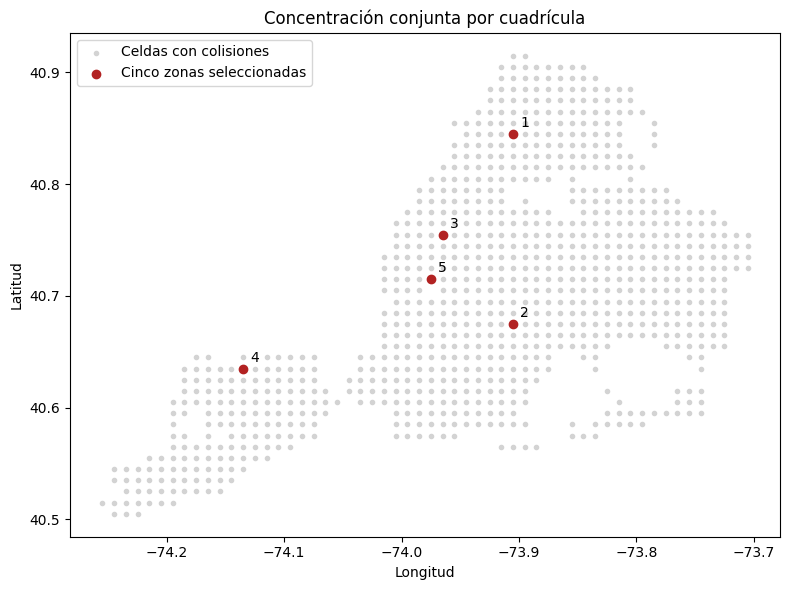

In [28]:
from pyspark.sql.window import Window

def por_cuadricula(df, lat, lon):
    return (df.filter(F.col(lat).between(40.49, 40.92) & F.col(lon).between(-74.27, -73.68))
        .withColumn("y", F.floor(F.col(lat) * 100))
        .withColumn("x", F.floor(F.col(lon) * 100)))

arrestos_zona = (por_cuadricula(arr_sem, "Latitude", "Longitude")
    .groupBy("x", "y").agg(F.count("*").alias("arrestos")))
colisiones_zona = (por_cuadricula(col_sem, "lat", "lon").groupBy("x", "y")
    .agg(F.count("*").alias("colisiones"), F.sum("fatal").alias("fatales"),
         F.avg(F.when(F.col("hora").isNotNull(), (F.col("hora").between(22, 23) | F.col("hora").between(0, 5)).cast("int"))).alias("proporcion_nocturna"),
         F.avg(((F.col("NUMBER OF PEDESTRIANS INJURED") + F.col("NUMBER OF PEDESTRIANS KILLED")
          + F.col("NUMBER OF CYCLIST INJURED") + F.col("NUMBER OF CYCLIST KILLED")) > 0)
            .cast("int")).alias("proporcion_vulnerables")))
zonas = colisiones_zona.join(arrestos_zona, ["x", "y"], "left").fillna(0, subset=["arrestos"])
q5 = (zonas.filter((F.col("arrestos") > 0) & (F.col("fatales") > 0))
    .withColumn("indice", (F.percent_rank().over(Window.orderBy("arrestos"))
        + F.percent_rank().over(Window.orderBy("fatales"))) / 2)
    .orderBy(F.desc("indice"), F.desc("fatales"), F.desc("arrestos"), "y", "x")
    .limit(5).select(((F.col("y") + .5) / 100).alias("latitud"),
        ((F.col("x") + .5) / 100).alias("longitud"), "arrestos", "fatales", "indice").toPandas())
q5.index = range(1, len(q5) + 1)
display(q5.round(4))

ubicaciones = zonas.select("x", "y").toPandas()
ax = plt.subplots(figsize=(8, 6))[1]
ax.scatter((ubicaciones["x"] + .5) / 100, (ubicaciones["y"] + .5) / 100,
           s=9, color="lightgrey", label="Celdas con colisiones")
ax.scatter(q5["longitud"], q5["latitud"], color="firebrick", label="Cinco zonas seleccionadas")
for puesto, fila in q5.iterrows():
    ax.annotate(puesto, (fila["longitud"], fila["latitud"]), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Longitud", ylabel="Latitud", title="Concentración conjunta por cuadrícula")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación.** Las dos celdas que encabezan la clasificación tienen dos colisiones fatales cada una y registran 1.584 y 1.107 arrestos, respectivamente. Los centros aproximados están en (40,845°, −73,905°) y (40,675°, −73,905°). El ranking indica coincidencia dentro de la misma cuadrícula y el mismo semestre.

### 6. Perfil demográfico de los arrestos según gravedad

Se trabaja con la gravedad reportada (V, M, F). Se presenta el perfil combinado más frecuente y las distribuciones separadas de edad, sexo y raza registrados. Las proporciones describen los arrestos del dataset.

,gravedad_reportada,AGE_GROUP,PERP_SEX,PERP_RACE,count
0,F,25-44,M,BLACK,12539
1,M,25-44,M,BLACK,17778
2,V,25-44,M,BLACK,570


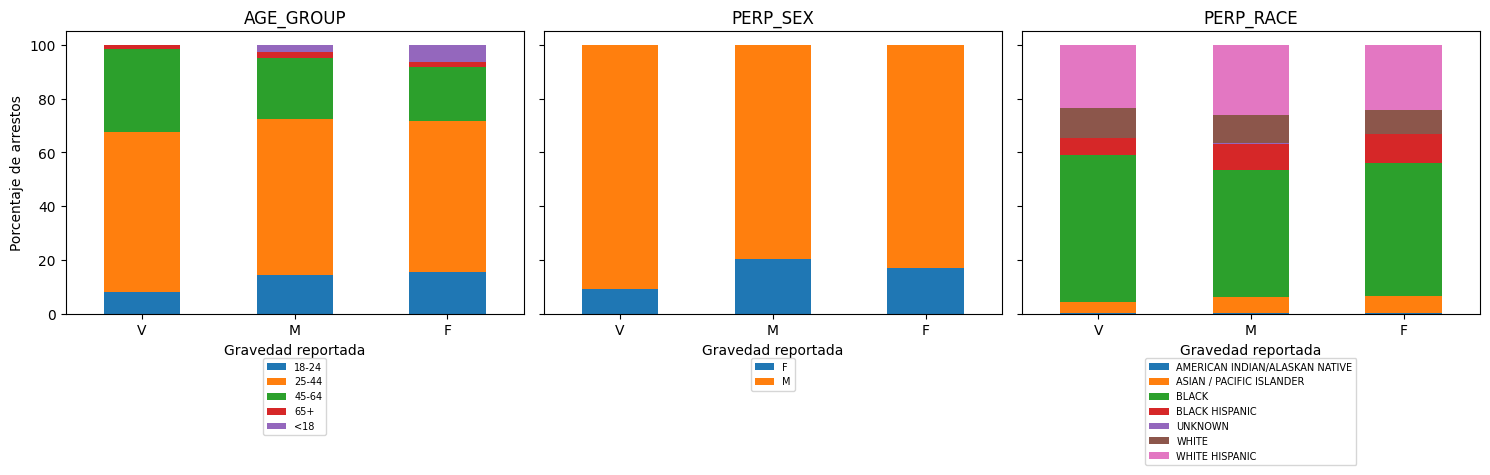

In [29]:
demograficas = ["AGE_GROUP", "PERP_SEX", "PERP_RACE"]
arrestos_perfil = arr_sem.filter(F.col("gravedad_reportada").isin("V", "M", "F"))
orden_perfil = Window.partitionBy("gravedad_reportada").orderBy(F.desc("count"), *demograficas)
perfiles = (arrestos_perfil.groupBy("gravedad_reportada", *demograficas).count()
    .withColumn("orden", F.row_number().over(orden_perfil))
    .filter(F.col("orden") == 1).drop("orden").orderBy("gravedad_reportada"))
display(perfiles.toPandas())
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, variable in zip(axes, demograficas):
    tabla = (arrestos_perfil.groupBy("gravedad_reportada", variable).count().toPandas()
        .pivot_table(index="gravedad_reportada", columns=variable, values="count",
                     aggfunc="sum", fill_value=0).reindex(["V", "M", "F"]))
    tabla.div(tabla.sum(axis=1), axis=0).mul(100).plot.bar(ax=ax, stacked=True, rot=0)
    ax.set(xlabel="Gravedad reportada", title=variable)
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.14))
axes[0].set_ylabel("Porcentaje de arrestos")
plt.tight_layout()
plt.show()

**Interpretación.** El perfil combinado más frecuente en las tres categorías fue el de personas de 25 a 44 años, sexo masculino y raza registrada como BLACK. Ese perfil aparece en 17.778 arrestos por delitos menores, 12.539 por felonías y 570 por violaciones. El resultado describe la composición de los arrestos registrados.

### 7. Colisiones por hora en Manhattan y Staten Island

Se comparan volúmenes y proporciones horarias durante el mismo semestre. Las proporciones dentro de cada condado permiten distinguir la forma del patrón horario del volumen total de colisiones.

,Colisiones,Hora pico,Colisiones en la hora pico
BOROUGH,,,
MANHATTAN,7347,16,507
STATEN ISLAND,1570,15,112


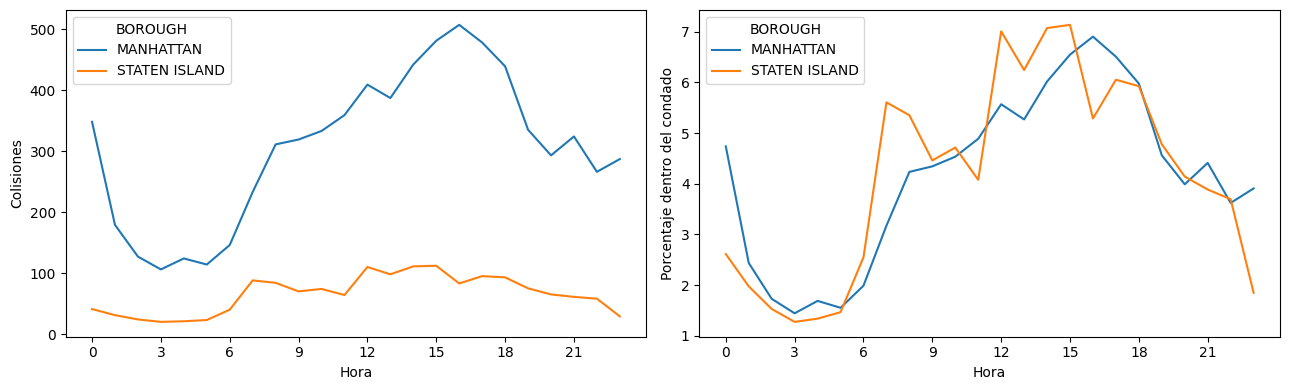

In [30]:
q7 = (col_sem.filter(F.col("BOROUGH").isin("MANHATTAN", "STATEN ISLAND") & F.col("hora").isNotNull())
    .groupBy("hora", "BOROUGH").count().toPandas())
horario = (q7.pivot(index="hora", columns="BOROUGH", values="count")
    .reindex(index=range(24), columns=["MANHATTAN", "STATEN ISLAND"]).fillna(0))
proporciones = horario.div(horario.sum(), axis=1) * 100
display(pd.DataFrame({"Colisiones": horario.sum(), "Hora pico": horario.idxmax(),
                      "Colisiones en la hora pico": horario.max()}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
horario.plot(ax=axes[0], ylabel="Colisiones", xlabel="Hora", xticks=range(0, 24, 3))
proporciones.plot(ax=axes[1], ylabel="Porcentaje dentro del condado", xlabel="Hora", xticks=range(0, 24, 3))
plt.tight_layout()
plt.show()

**Interpretación.** Manhattan registró 7.347 colisiones con hora informada, frente a 1.570 en Staten Island. El mayor conteo por hora fue a las 16:00 en Manhattan (507 colisiones) y a las 15:00 en Staten Island (112).

---
## Fases IV y V (CRISP-DM) — Modelado y Evaluación en Spark MLlib
### Numeral 3 — Selección de técnicas de aprendizaje de máquina

Para responder las preguntas sobre fatalidad vial y perfiles territoriales en Nueva York, se seleccionaron dos técnicas de **Apache Spark MLlib** ejecutadas de forma distribuida sobre el clúster:

- **Técnica supervisada — Regresión Logística (`LogisticRegression`).** La pregunta 8 estudia qué características se asocian con que una colisión registrada tenga al menos un fallecido (`label = 1`). El historial proporciona una etiqueta binaria para cada siniestro. La regresión logística permite estimar la probabilidad calibrada de ese desenlace y examinar directamente el signo y la magnitud de los coeficientes por familia de variables, manteniendo interpretabilidad para los tomadores de decisiones de *Vision Zero*.
- **Técnica no supervisada — K-Means (`KMeans`).** El objetivo territorial es identificar zonas de la ciudad con perfiles similares de siniestralidad y criminalidad, junto con diferencias en la proporción de colisiones nocturnas o con peatones y ciclistas afectados. Dado que las cuadrículas espaciales carecen de etiquetas predefinidas de prioridad, K-Means permite segmentarlas objetivamente en el espacio multivariado estandarizado.

### Numerales 4, 5 y 6 (Modelo Supervisado) y Pregunta 8 — Variables asociadas con la fatalidad de una colisión

#### Numeral 4 — Preparación de datos para modelado:
- **4.a Eliminación de características fuertemente correlacionadas:** Se calcula la matriz de correlación de Pearson en Spark MLlib (`Correlation.corr`) sobre las variables numéricas candidatas y se descartan aquellas con $|r| \ge 0.90$.
- **4.b Normalización de variables numéricas:** Se aplica `StandardScaler(withMean=True, withStd=True)` ajustado exclusivamente sobre el conjunto de entrenamiento (2024) dentro de un `Pipeline` de MLlib para evitar fuga de información (*data leakage*), junto con codificación cíclica trigonométrica de la hora (`hora_seno`, `hora_coseno`).
- **4.c Selección de variables según criterio de negocio:** El modelo recibe ubicación (`lat`, `lon`), hora cíclica (`hora_seno`, `hora_coseno`), tipo de vehículo primario (`VEHICLE TYPE CODE 1`) y factor contribuyente primario (`CONTRIBUTING FACTOR VEHICLE 1`) codificados mediante `StringIndexer` y `OneHotEncoder`. Se excluyen explícitamente los conteos de heridos y fallecidos para evitar fuga directa de la variable objetivo.

#### Numeral 5 y 6 — Aplicación en el clúster y Evaluación con múltiples parámetros:
Se entrena con el año 2024 (`83.698` colisiones), se comparan hiperparámetros de regularización (`regParam` $\in \{0.01, 0.10, 1.00\}$) y umbrales de clasificación en 2025 (`82.918` colisiones), y se evalúa en el primer semestre de 2026 (`40.373` colisiones) mediante **AUPRC**, **AUROC**, **Precisión**, **Exhaustividad (Recall)** y **F1**.

In [31]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import BinaryClassificationEvaluator, ClusteringEvaluator
from pyspark.ml.feature import OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.stat import Correlation
import math

def seleccionar_numericas(df, candidatas, limite=.90):
    # Prioridad de las variables dada por el orden de la lista.
    vector = VectorAssembler(inputCols=candidatas, outputCol="vector_correlacion")
    matriz = (Correlation.corr(vector.transform(df), "vector_correlacion")
              .first()[0].toArray())
    print("Correlación de Pearson")
    display(pd.DataFrame(matriz, index=candidatas, columns=candidatas).round(2))
    desviaciones = df.agg(*[F.stddev_pop(c).alias(c) for c in candidatas]).first().asDict()
    elegidas = []
    for j, c in enumerate(candidatas):
        if desviaciones[c] and all(abs(matriz[j, i]) < limite for i in elegidas):
            elegidas.append(j)
    seleccion = [candidatas[i] for i in elegidas]
    if not seleccion:
        raise ValueError("No quedaron variables numéricas con variación.")
    print("Variables numéricas seleccionadas:", seleccion)
    return seleccion

modelo_col = (col_analisis.filter(F.col("fecha").between("2024-01-01", fin))
    .filter(F.col("coord_valida") & F.col("hora").isNotNull())
    .select("fecha", "lat", "lon", "hora",
        F.col("VEHICLE TYPE CODE 1").alias("vehiculo"),
        F.col("CONTRIBUTING FACTOR VEHICLE 1").alias("factor"),
        (F.col("NUMBER OF PERSONS KILLED") > 0).cast("double").alias("label"))
    .fillna("SIN_DATO", subset=["vehiculo", "factor"])
    .withColumn("hora_seno", F.sin(F.col("hora") * math.tau / 24))
    .withColumn("hora_coseno", F.cos(F.col("hora") * math.tau / 24))
    .cache())

entrenamiento = modelo_col.filter(F.year("fecha") == 2024)
validacion = modelo_col.filter(F.year("fecha") == 2025)
prueba = modelo_col.filter(F.year("fecha") == 2026)
modelo_col.groupBy(F.year("fecha").alias("anio"), "label").count().orderBy("anio", "label").show()
numericas_lr = seleccionar_numericas(entrenamiento, ["hora_seno", "hora_coseno", "lat", "lon"])
categoricas_lr = ["vehiculo", "factor"]
indexadas_lr = [f"{c}_idx" for c in categoricas_lr]
codificadas_lr = [f"{c}_ohe" for c in categoricas_lr]
preparacion_lr = Pipeline(stages=[
    VectorAssembler(inputCols=numericas_lr, outputCol="numericos"),
    StandardScaler(inputCol="numericos", outputCol="numericos_escalados", withMean=True, withStd=True),
    StringIndexer(inputCols=categoricas_lr, outputCols=indexadas_lr, handleInvalid="keep"),
    OneHotEncoder(inputCols=indexadas_lr, outputCols=codificadas_lr),
    VectorAssembler(inputCols=["numericos_escalados", *codificadas_lr], outputCol="features")
]).fit(entrenamiento)
clases = {r["label"]: r["count"] for r in entrenamiento.groupBy("label").count().collect()}
if not clases.get(0.0) or not clases.get(1.0):
    raise ValueError("El entrenamiento necesita colisiones fatales y no fatales.")
train_lr = (preparacion_lr.transform(entrenamiento)
    .select("label", "features")
    .withColumn("peso", F.when(F.col("label") == 1, clases[0.0] / clases[1.0]).otherwise(1.0))
    .cache())
val_lr = preparacion_lr.transform(validacion).select("label", "features").cache()
test_lr = preparacion_lr.transform(prueba).select("label", "features").cache()

+----+-----+-----+
|anio|label|count|
+----+-----+-----+
|2024|  0.0|83479|
|2024|  1.0|  219|
|2025|  0.0|82713|
|2025|  1.0|  205|
|2026|  0.0|40271|
|2026|  1.0|  102|
+----+-----+-----+

Correlación de Pearson


,hora_seno,hora_coseno,lat,lon
hora_seno,1.00,-0.08,0.01,0.02
hora_coseno,-0.08,1.00,0.03,0.04
lat,0.01,0.03,1.00,0.35
lon,0.02,0.04,0.35,1.00


Variables numéricas seleccionadas: ['hora_seno', 'hora_coseno', 'lat', 'lon']


,regParam,AUPRC validación
0,0.01,0.004247
1,0.10,0.004604
2,1.00,0.004822


,umbral,VP,FP,FN,VN,precision,recall,F1
0,0.10,205,82713,0,0,0.0025,1.0000,0.0049
1,0.25,205,82713,0,0,0.0025,1.0000,0.0049
2,0.40,201,76490,4,6223,0.0026,0.9805,0.0052
3,0.55,98,27394,107,55319,0.0036,0.4780,0.0071
4,0.70,0,20,205,82693,0.0000,0.0000,0.0000
5,0.85,0,0,205,82713,0.0000,0.0000,0.0000
6,0.95,0,0,205,82713,0.0000,0.0000,0.0000


regParam elegido: 1.0 | umbral elegido: 0.55
AUPRC en prueba: 0.0042
AUROC en prueba: 0.5397
Proporción fatal en prueba: 0.0025


,umbral,VP,FP,FN,VN,precision,recall,F1
0,0.55,50,16382,52,23889,0.003,0.4902,0.006


,variable,coeficiente,familia,magnitud
130,vehiculo_ohe_AMBULANE,-0.5000,Tipo de vehículo 1,0.5000
335,factor_ohe_OTHER LIGHTING DEFECTS,0.4098,Factor contribuyente 1,0.4098
1,hora_coseno,0.0752,Hora,0.0752
2,lat,0.0070,Coordenadas,0.0070


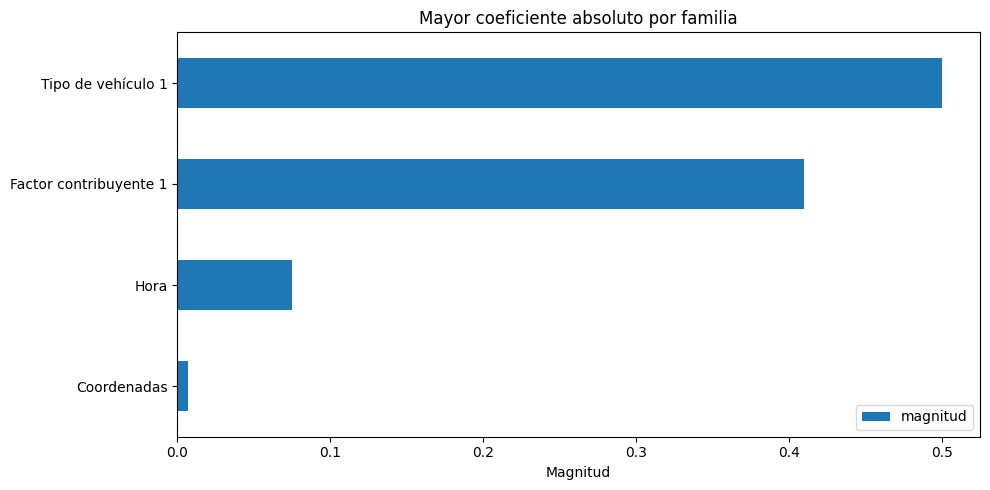

In [32]:
auprc = BinaryClassificationEvaluator(metricName="areaUnderPR")
aucroc = BinaryClassificationEvaluator(metricName="areaUnderROC")
opciones = []
for regularizacion in [.01, .1, 1.0]:
    modelo = LogisticRegression(weightCol="peso", regParam=regularizacion, maxIter=50).fit(train_lr)
    opciones.append((regularizacion, auprc.evaluate(modelo.transform(val_lr)), modelo))
display(pd.DataFrame([(r, m) for r, m, _ in opciones], columns=["regParam", "AUPRC validación"]))
reg_elegida, _, mejor_lr = max(opciones, key=lambda x: x[1])

def evaluar_umbrales(pred, umbrales):
    score = vector_to_array(F.col("probability"))[1]
    positivo = F.col("label") == 1
    conteos = pred.agg(*[
        F.sum(F.when(condicion, 1).otherwise(0)).alias(f"{nombre}_{i}")
        for i, u in enumerate(umbrales)
        for nombre, condicion in [("VP", positivo & (score >= u)),
                                   ("FP", ~positivo & (score >= u)),
                                   ("FN", positivo & (score < u)),
                                   ("VN", ~positivo & (score < u))]
    ]).first().asDict()
    filas = []
    for i, u in enumerate(umbrales):
        vp, fp, fn, vn = [conteos[f"{nombre}_{i}"] for nombre in ("VP", "FP", "FN", "VN")]
        precision = vp / (vp + fp) if vp + fp else 0
        recall = vp / (vp + fn) if vp + fn else 0
        f1 = 2 * vp / (2 * vp + fp + fn) if 2 * vp + fp + fn else 0
        filas.append(dict(umbral=u, VP=vp, FP=fp, FN=fn, VN=vn,
                          precision=precision, recall=recall, F1=f1))
    return pd.DataFrame(filas)

rendimiento_val = evaluar_umbrales(mejor_lr.transform(val_lr), [.10, .25, .40, .55, .70, .85, .95])
display(rendimiento_val.round(4))
umbral_elegido = rendimiento_val.sort_values(["F1", "recall"], ascending=False).iloc[0]["umbral"]
pred_prueba = mejor_lr.transform(test_lr)
print(f"regParam elegido: {reg_elegida} | umbral elegido: {umbral_elegido:.2f}")
print(f"AUPRC en prueba: {auprc.evaluate(pred_prueba):.4f}")
print(f"AUROC en prueba: {aucroc.evaluate(pred_prueba):.4f}")
print(f"Proporción fatal en prueba: {test_lr.agg(F.avg('label')).first()[0]:.4f}")
display(evaluar_umbrales(pred_prueba, [float(umbral_elegido)]).round(4))

atributos = test_lr.schema["features"].metadata.get("ml_attr", {}).get("attrs", {})
nombres = {a["idx"]: a["name"] for grupo in atributos.values() for a in grupo}
nombres.update(enumerate(numericas_lr))
# El interés es descriptivo. Un grupo con más categorías ofrece más coeficientes candidatos.
coeficientes = pd.DataFrame({
    "variable": [nombres.get(i, f"Categoría codificada {i}") for i in range(mejor_lr.coefficients.size)],
    "coeficiente": mejor_lr.coefficients.toArray()
})
def familia(nombre):
    if nombre.startswith("vehiculo_ohe_"):
        return "Tipo de vehículo 1"
    if nombre.startswith("factor_ohe_"):
        return "Factor contribuyente 1"
    if nombre in {"lat", "lon"}:
        return "Coordenadas"
    return "Hora" if nombre.startswith("hora_") else "Categoría codificada"
coeficientes["familia"] = coeficientes["variable"].map(familia)
coeficientes["magnitud"] = coeficientes["coeficiente"].abs()
q8 = (coeficientes.sort_values(["magnitud", "variable"], ascending=[False, True])
    .groupby("familia", sort=False).head(1))
display(q8.round(4))
barras(q8, "familia", ["magnitud"], "Mayor coeficiente absoluto por familia", "Magnitud",
       horizontal=True)

#### Interpretación de la regresión logística

La regularización de 1,00 obtuvo la mayor AUPRC en validación (0,004822). El umbral de 0,55 se eligió por F1 en validación. En la prueba temporal, el modelo obtuvo una AUPRC de 0,0042 frente a una prevalencia de 0,0025 y una AUROC de 0,5397, cerca del nivel de azar (0,5).

Con ese umbral identificó 50 de las 102 colisiones fatales (exhaustividad del 49,02 %), dejó 52 sin detectar y generó 16.382 falsos positivos. La precisión fue del 0,30 % y el F1 fue de 0,006. La mejora sobre la prevalencia es pequeña en términos absolutos. El modelo tiene capacidad predictiva limitada con estas variables.

En la gráfica, el tipo de vehículo y el factor contribuyente contienen los mayores coeficientes en magnitud. Las categorías registradas como AMBULANE (−0,5000) y OTHER LIGHTING DEFECTS (+0,4098) son ejemplos del ajuste. La gráfica usa valores absolutos, por lo que el signo se consulta en la tabla. Estos coeficientes describen asociaciones del modelo ajustado y deben leerse junto con el bajo rendimiento en prueba.

### Numerales 4, 5 y 6 (Modelo No Supervisado) — Perfiles territoriales de zonas con K-Means

Se agrupan las cuadrículas de $0.01^\circ \times 0.01^\circ$ con al menos diez colisiones en el primer semestre de 2026 (`699` zonas activas):
- **4.a Correlación de Pearson:** Se verifica la matriz de correlación entre `log_colisiones`, `log_arrestos` (transformación $\log(1+x)$ para mitigar asimetría positiva), `proporcion_nocturna` y `proporcion_vulnerables` ($|r|_{\max} = 0.78 < 0.90$).
- **4.b Normalización:** Escalado a media cero y varianza unitaria con `StandardScaler` para evitar que una variable domine la distancia euclídea.
- **4.c Selección de variables de negocio:** Se integran las cuatro dimensiones operativas (volumen vial, carga policial, nocturnidad y afectación a peatones/ciclistas).
- **5 y 6 Aplicación y Evaluación en MLlib:** Se evalúan tres valores del hiperparámetro $k \in \{2, 3, 4\}$ mediante el **coeficiente de Silhouette** con distancia euclídea al cuadrado (`ClusteringEvaluator`).

Correlación de Pearson


,log_colisiones,log_arrestos,proporcion_nocturna,proporcion_vulnerables
log_colisiones,1.00,0.78,0.07,0.35
log_arrestos,0.78,1.00,-0.02,0.43
proporcion_nocturna,0.07,-0.02,1.00,-0.19
proporcion_vulnerables,0.35,0.43,-0.19,1.00


Variables numéricas seleccionadas: ['log_colisiones', 'log_arrestos', 'proporcion_nocturna', 'proporcion_vulnerables']


,k,silhouette
0,2,0.473409
1,3,0.459737
2,4,0.369069


k elegido: 2 | silhouette: 0.473


,prediction,zonas,colisiones_promedio,arrestos_promedio,fatales_promedio,proporcion_nocturna,proporcion_vulnerables
0,0,351,83.815,365.991,0.171,0.203,0.173
1,1,348,29.296,35.330,0.101,0.210,0.087


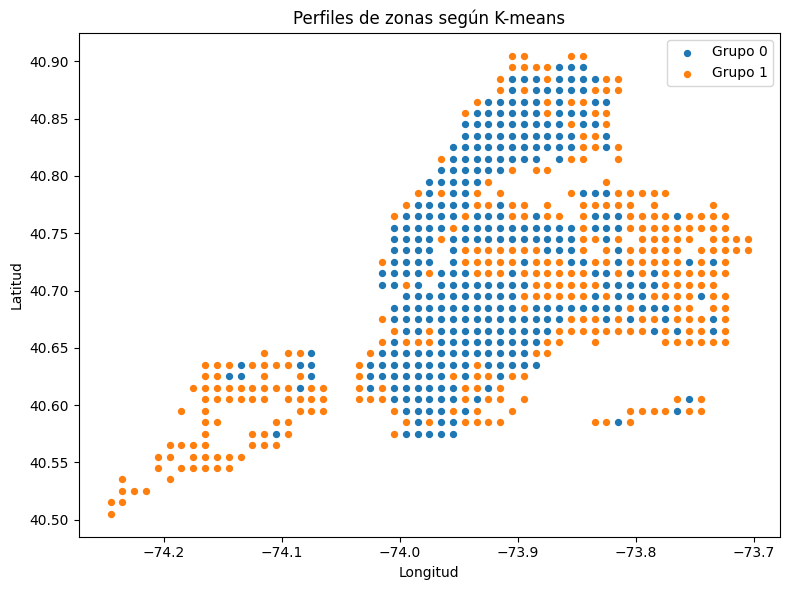

In [33]:
zonas_ml = (zonas.filter(F.col("colisiones") >= 10).dropna(subset=["proporcion_nocturna"])
    .withColumn("log_colisiones", F.log1p("colisiones"))
    .withColumn("log_arrestos", F.log1p("arrestos")).cache())
variables_km = seleccionar_numericas(zonas_ml,
    ["log_colisiones", "log_arrestos", "proporcion_nocturna", "proporcion_vulnerables"])
pipeline_km = Pipeline(stages=[
    VectorAssembler(inputCols=variables_km, outputCol="perfil"),
    StandardScaler(inputCol="perfil", outputCol="features", withStd=True, withMean=True)
]).fit(zonas_ml)
entrada_km = pipeline_km.transform(zonas_ml).cache()
silhouette = ClusteringEvaluator(metricName="silhouette", distanceMeasure="squaredEuclidean")
alternativas_km = []
for k in [2, 3, 4]:
    modelo_km = KMeans(k=k, seed=42).fit(entrada_km)
    alternativas_km.append((k, silhouette.evaluate(modelo_km.transform(entrada_km)), modelo_km))
display(pd.DataFrame([(k, s) for k, s, _ in alternativas_km], columns=["k", "silhouette"]))
k_final, s_final, modelo_km = max(alternativas_km, key=lambda x: x[1])
print(f"k elegido: {k_final} | silhouette: {s_final:.3f}")
asignaciones = modelo_km.transform(entrada_km)
resumen_km = (asignaciones.groupBy("prediction")
    .agg(F.count("*").alias("zonas"), F.avg("colisiones").alias("colisiones_promedio"),
         F.avg("arrestos").alias("arrestos_promedio"), F.avg("fatales").alias("fatales_promedio"),
         F.avg("proporcion_nocturna").alias("proporcion_nocturna"),
         F.avg("proporcion_vulnerables").alias("proporcion_vulnerables"))
    .orderBy("prediction").toPandas())
display(resumen_km.round(3))
mapa_km = asignaciones.select("x", "y", "prediction").toPandas()
ax = plt.subplots(figsize=(8, 6))[1]
for grupo, puntos in mapa_km.groupby("prediction"):
    ax.scatter((puntos["x"] + .5) / 100, (puntos["y"] + .5) / 100, s=18, label=f"Grupo {grupo}")
ax.set(xlabel="Longitud", ylabel="Latitud", title="Perfiles de zonas según K-means")
ax.legend()
plt.tight_layout()
plt.show()

#### Interpretación del agrupamiento

Entre las alternativas evaluadas, dos grupos tuvieron el mayor silhouette (0,4734), seguido por tres (0,4597) y cuatro (0,3691). La diferencia frente a tres grupos fue pequeña. Se conservaron las cuatro variables porque la mayor correlación absoluta entre ellas fue de 0,78, inferior al umbral de 0,90.

El grupo de mayor volumen reunió 351 zonas y promedió 83,8 colisiones y 366,0 arrestos por zona. El otro reunió 348 zonas y promedió 29,3 colisiones y 35,3 arrestos. La proporción media de colisiones con peatones o ciclistas afectados fue del 17,3 % y del 8,7 %, respectivamente. La proporción nocturna fue similar (20,3 % y 21,0 %).

Los grupos distinguen perfiles de volumen y composición dentro de las cuadrículas analizadas. Las cifras son descriptivas y provienen de conteos por zona, sin ajuste por población ni por volumen de tráfico.

---
## 8. Incrementales (bono +0.5): Web Scraping del NYS Department of Health y API climática

Esta sección desarrolla los dos incrementales opcionales sobre la primera entrega (+0.25 cada uno):

| Incremental | Requisito | Dónde se cumple |
|---|---|---|
| 1. Web scraping | Extraer los datos del enlace del NYS Department of Health (tasas de cáncer por PUMA) y generar al menos un gráfico/tabla | 8.1 (extracción), 8.2 (tabla y gráficos de los datos extraídos) |
| 2. Información climática por API | Extraer datos de la API de OpenWeather y generar al menos un gráfico/tabla | 8.4 (extracción), 8.5 (tabla y gráfico de los datos extraídos) |

Los cruces con pobreza, arrestos y colisiones (8.3 y 8.6) son un complemento exploratorio que conecta ambas fuentes con el problema del proyecto.

| Fuente | Técnica | Qué aporta | Para qué se usa |
|---|---|---|---|
| NYS Department of Health – *Cancer Statistics Dashboard: Rate by PUMA* (NYS Cancer Registry) | Web scraping (`requests`): se localiza el dashboard de Tableau incrustado en la página y se descarga su CSV | Tasa de incidencia de cáncer por vecindario (PUMA) y condado | Contexto de salud por vecindario; cruce exploratorio con pobreza y arrestos por condado |
| OpenWeather *One Call API 3.0* (`day_summary`) | API REST | Temperatura, precipitación y viento diarios en NYC | Contexto ambiental de las colisiones y los arrestos |

**Aclaración sobre la fuente del NYS Department of Health.** La página `ratebyPUMA.htm` no contiene una tabla HTML: incrusta un *dashboard* de Tableau Public. Por eso no se puede leer con `BeautifulSoup` como una tabla; el código localiza la vista de Tableau a partir del propio HTML de la página y descarga su CSV. Además, el dashboard publica **tasas de cáncer por PUMA, no la población** de cada vecindario. Por eso la normalización por 100,000 habitantes de arrestos y colisiones sigue usando la población estimada con `PWGTP` (numeral 4), y esta fuente se emplea como contexto de salud por vecindario.

**Aclaración sobre el clima.** `day_summary` entrega un registro por fecha y por coordenada, y el plan gratuito *One Call by Call* admite 1,000 llamadas por día. Por eso se consulta un único punto (centro de NYC) y solo las fechas realmente necesarias (año de referencia de colisiones y rango de arrestos). Las respuestas se guardan en caché para no volver a gastar llamadas. Si no hay API key o la llamada falla, el código recurre a **Open-Meteo** (archivo histórico gratuito y sin clave) con las mismas columnas.

> Para usar OpenWeather, definir la clave antes de iniciar Jupyter: `export OPENWEATHER_API_KEY="..."`.

In [34]:
# Dependencias del scraping (en el clúster se instalan en el entorno de usuario)
!pip install requests

Defaulting to user installation because normal site-packages is not writeable


### 8.1 Incremental 1 — Web scraping: tasas de cáncer por vecindario (NYS Department of Health)

La página solo contiene una imagen de vista previa y el *dashboard* de Tableau Public "Rate by PUMA". El flujo es:

1. Descargar el HTML de `ratebyPUMA.htm` y extraer de él el libro y la hoja de Tableau (aparecen en la ruta de la imagen de vista previa).
2. Pedir a Tableau Public el CSV de esa hoja (`.../views/<libro>/<hoja>.csv`).
3. Normalizar las columnas (condado, PUMA, sitio de cáncer, sexo, tasa) y quedarse con **todos los sitios combinados, ambos sexos**, una fila por PUMA.

**Plan B y C.** Si el scraping en vivo falla, se usa la copia en caché `cancer_tasas_puma_nyc.csv`; si tampoco existe, se lee el archivo descargado a mano desde el dashboard (*Download > Data > Crosstab*), guardado como `7__WS_table.csv`. Ese archivo viene en UTF-16, separado por tabulaciones y con **dos filas de encabezado** (grupo de sexo y medida: Count, Rate, Lci, Uci), por lo que se convierte a formato largo (una fila por PUMA, sitio y sexo).

Si la estructura del CSV cambia, el error muestra las columnas disponibles para fijarlas en las variables `COL_*` / `FILTRO_*` del inicio de la celda.

In [35]:
import os, io, re, time, html, requests
from datetime import date
import pandas as pd
import numpy as np

URL_PAGINA   = "https://www.health.ny.gov/statistics/cancer/registry/ratebyPUMA.htm"
CACHE_CANCER = "cancer_tasas_puma_nyc.csv"   # copia local de lo extraído (plan B)
CSV_MANUAL   = "7__WS_table.csv"             # crosstab descargado a mano del dashboard (plan C)
HEADERS = {"User-Agent": "Mozilla/5.0 (proyecto academico PUJ - Procesamiento de Datos a Gran Escala)"}

# Libro y hoja de Tableau conocidos; solo se usan si no se pueden leer del HTML de la página
LIBRO_TABLEAU, HOJA_TABLEAU = "cancerstatisticreportcounty", "7_RatebyPUMA"

# Si la detección automática falla, escribir aquí el nombre exacto de la columna / el valor a filtrar
COL_BORO = COL_PUMA = COL_TASA = COL_SEXO = COL_SITIO = COL_PERIODO = None
FILTRO_SITIO = FILTRO_SEXO = None

# Nombres de condado (o de borough) del dashboard -> nombres usados en el resto del notebook
MAPA_BORO_WEB = {
    "BRONX": "BRONX", "THE BRONX": "BRONX",
    "BROOKLYN": "BROOKLYN", "KINGS": "BROOKLYN", "KINGS (BROOKLYN)": "BROOKLYN",
    "MANHATTAN": "MANHATTAN", "NEW YORK": "MANHATTAN", "NEW YORK (MANHATTAN)": "MANHATTAN",
    "QUEENS": "QUEENS",
    "STATEN ISLAND": "STATEN ISLAND", "RICHMOND": "STATEN ISLAND", "RICHMOND (STATEN ISLAND)": "STATEN ISLAND",
}
# Los códigos PUMA de NYC empiezan por 37 (Bronx), 38 (Manhattan), 39 (Staten Island), 40 (Brooklyn), 41 (Queens)
BORO_POR_PREFIJO = {"37": "BRONX", "38": "MANHATTAN", "39": "STATEN ISLAND", "40": "BROOKLYN", "41": "QUEENS"}

def descargar(url, reintentos=3, espera=3):
    # Descarga con reintentos; devuelve None si no hay acceso.
    for i in range(1, reintentos + 1):
        try:
            r = requests.get(url, headers=HEADERS, timeout=60)
            r.raise_for_status()
            return r
        except requests.RequestException as e:
            print(f"Intento {i}/{reintentos} fallido: {e}")
            time.sleep(espera)
    return None

def url_csv_tableau(html_pagina):
    # La página solo trae la imagen de vista previa del dashboard; de su ruta se obtiene libro y hoja.
    texto = html.unescape(html_pagina or "")                      # la ruta viene con "&#47;" en lugar de "/"
    m = re.search(r"tableau\.com/static/images/\w+/([^/\"'\s]+)/([^/\"'\s]+)/", texto)
    libro, hoja = (m.group(1), m.group(2)) if m else (LIBRO_TABLEAU, HOJA_TABLEAU)
    return f"https://public.tableau.com/views/{libro}/{hoja}.csv?:showVizHome=no"

def leer_csv_bytes(contenido):
    # Lee un CSV de Tableau (UTF-8 o UTF-16 con tabulaciones). Si trae dos filas de encabezado
    # (grupo de sexo + medida: Count, Rate, Lci, Uci) lo convierte a formato largo.
    for enc in ("utf-8-sig", "utf-16", "latin-1"):
        try:
            plano = pd.read_csv(io.BytesIO(contenido), encoding=enc, sep=None, engine="python")
        except Exception:
            continue
        if plano.shape[1] <= 1:
            continue
        try:
            doble = pd.read_csv(io.BytesIO(contenido), encoding=enc, sep=None, engine="python", header=[0, 1])
            medidas = {str(c[1]).strip() for c in doble.columns}
            if {"Rate", "Count"} <= medidas:
                return crosstab_a_largo(doble)
        except Exception:
            pass
        return plano
    raise ValueError("No se pudo interpretar el CSV descargado.")

def crosstab_a_largo(doble):
    # Columnas: (', County'), (', Puma'), (', Cancer'), luego (<sexo>, Count/Rate/Lci/Uci) -> una fila por PUMA, sitio y sexo.
    ids = [c for c in doble.columns if not str(c[1]).strip() in {"Count", "Rate", "Lci", "Uci"}]
    nombres_id = [str(c[1]).strip() for c in ids]
    base = doble[ids].copy()
    base.columns = nombres_id
    partes = []
    for sexo in dict.fromkeys(str(c[0]).strip() for c in doble.columns if c not in ids):
        bloque = base.copy()
        bloque["Sex"] = sexo
        for medida in ["Count", "Rate", "Lci", "Uci"]:
            col = next(c for c in doble.columns if c not in ids and str(c[0]).strip() == sexo and str(c[1]).strip() == medida)
            bloque[medida] = pd.to_numeric(doble[col].astype(str).str.replace(",", ""), errors="coerce")
        partes.append(bloque)
    return pd.concat(partes, ignore_index=True)

def buscar_col(df, patrones, excluir=()):
    for c in df.columns:
        n = str(c).lower()
        if any(p in n for p in patrones) and not any(x in n for x in excluir):
            return c
    return None

def normalizar_cancer(df):
    # Devuelve un DataFrame con: BORO, puma, tasa (+ sexo, sitio, periodo si existen en el dashboard).
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]

    # Formato largo típico de Tableau (Measure Names / Measure Values) -> formato ancho
    if {"Measure Names", "Measure Values"} <= set(df.columns):
        idx = [c for c in df.columns if c not in ("Measure Names", "Measure Values")]
        df = (df.pivot_table(index=idx, columns="Measure Names", values="Measure Values", aggfunc="first")
                .reset_index())
        df.columns.name = None

    c_puma = COL_PUMA or buscar_col(df, ["puma", "neighborhood"], excluir=["code", "#", "id", "number"])
    c_tasa = COL_TASA or buscar_col(df, ["rate"], excluir=["lower", "upper", "ci", "confidence"])
    c_boro = COL_BORO or buscar_col(df, ["borough", "boro", "county"])
    c_cod  = buscar_col(df, ["puma code", "puma #", "puma id", "puma number", "puma_code"])
    c_sexo = COL_SEXO or buscar_col(df, ["sex", "gender"])
    c_sit  = COL_SITIO or buscar_col(df, ["site", "cancer type", "cancer"], excluir=["rate"])
    c_per  = COL_PERIODO or buscar_col(df, ["year", "period"])

    if not (c_puma and c_tasa):
        raise ValueError("No se identificaron las columnas de PUMA y tasa. Defínelas en COL_PUMA / COL_TASA. "
                         f"Columnas disponibles: {list(df.columns)}")

    out = pd.DataFrame({"puma": df[c_puma].astype(str).str.strip()})
    out["tasa"] = pd.to_numeric(df[c_tasa].astype(str).str.replace(r"[^\d.\-]", "", regex=True), errors="coerce")
    if c_boro:
        out["BORO"] = (df[c_boro].astype(str).str.strip().str.upper()
                       .str.replace(r"\s+COUNTY$", "", regex=True)          # "Kings County" -> "KINGS"
                       .map(lambda b: MAPA_BORO_WEB.get(b, b)))
    elif c_cod:
        out["BORO"] = df[c_cod].astype(str).str.extract(r"(\d{2})")[0].map(BORO_POR_PREFIJO)
    else:
        raise ValueError("No hay columna de condado ni de código PUMA. Defínela en COL_BORO. "
                         f"Columnas disponibles: {list(df.columns)}")
    out["sexo"]    = df[c_sexo].astype(str).str.strip() if c_sexo else None
    out["sitio"]   = df[c_sit].astype(str).str.strip() if c_sit else None
    out["periodo"] = df[c_per].astype(str).str.strip() if c_per else None
    return out.dropna(subset=["tasa"]).reset_index(drop=True)

def filtrar_total(df):
    # Deja "todos los sitios, ambos sexos" (o el filtro fijado a mano) y avisa si debe elegirse a mano.
    notas = []
    for col, fijo, patron, etiqueta in [
        ("sitio", FILTRO_SITIO, r"\ball\b|total|todos", "sitio de cáncer"),
        ("sexo",  FILTRO_SEXO,  r"both|males? and females?|total|\ball\b|ambos", "sexo")]:
        if df[col].isna().all():
            continue
        valores = list(df[col].dropna().unique())
        if len(valores) == 1:
            continue
        elegido = fijo or next((v for v in valores if re.search(patron, v, re.I)), None)
        if elegido is None:
            elegido = valores[0]
            notas.append(f"ADVERTENCIA: no se encontró un valor 'total' en {etiqueta}; se usó '{elegido}'. "
                         f"Opciones: {valores[:8]}. Fija FILTRO_{col.upper()} si quieres otro.")
        df = df[df[col] == elegido]
        notas.append(f"{etiqueta} = {elegido}")
    return df, notas

# --- Obtención de los datos: scraping en vivo -> caché -> CSV descargado a mano ---
pagina = descargar(URL_PAGINA)
url_csv = url_csv_tableau(pagina.text if pagina is not None else "")
print("Vista de Tableau:", url_csv)

def desde_web():
    resp = descargar(url_csv)
    if resp is None:
        raise ConnectionError("sin acceso al dashboard")
    return leer_csv_bytes(resp.content)

def desde_archivo(ruta):
    with open(ruta, "rb") as f:
        return leer_csv_bytes(f.read())

candidatos = [("scraping en vivo (Tableau Public)", desde_web)]
if os.path.exists(CACHE_CANCER):
    candidatos.append(("caché local", lambda: pd.read_csv(CACHE_CANCER)))
if os.path.exists(CSV_MANUAL):
    candidatos.append((f"archivo descargado a mano ({CSV_MANUAL})", lambda: desde_archivo(CSV_MANUAL)))

cancer_raw, cancer_puma, fuente_cancer = None, None, None
for nombre, cargar in candidatos:
    try:
        crudo = cargar()
        cancer_puma = normalizar_cancer(crudo)          # valida que las columnas se reconozcan
        cancer_raw, fuente_cancer = crudo, nombre
        break
    except Exception as e:
        print(f"Fuente '{nombre}' no disponible o no reconocida: {e}")

if cancer_raw is None:
    raise RuntimeError("Sin acceso al dashboard y sin caché ni archivo local. Habilita la red del clúster, o descarga "
                       f"el crosstab desde {URL_PAGINA} (Download > Data) y guárdalo como {CSV_MANUAL}.")
if fuente_cancer.startswith("scraping"):
    cancer_raw.to_csv(CACHE_CANCER, index=False)

cancer_base, notas = filtrar_total(cancer_puma)
cancer_base = cancer_base.drop_duplicates("puma").reset_index(drop=True)

print("Fuente de los datos:", fuente_cancer)
print("Columnas tras la lectura:", list(cancer_raw.columns))
print("Filtros aplicados:", "; ".join(notas) if notas else "ninguno (el CSV ya trae una sola serie)")
print("PUMA leídos:", len(cancer_base), "(se esperan 55)")
print("Periodo:", ", ".join(cancer_base["periodo"].dropna().unique()) if cancer_base["periodo"].notna().any() else "no viene en el archivo; ver nota del dashboard")
print(cancer_base.groupby("BORO")["tasa"].agg(["count", "mean"]).round(1))
cancer_base.head(10)

Vista de Tableau: https://public.tableau.com/views/cancerstatisticreportcounty/7_RatebyPUMA.csv?:showVizHome=no
Fuente de los datos: scraping en vivo (Tableau Public)
Columnas tras la lectura: ['County', 'Puma', 'Rate Supp', 'Rate', 'Rate.1']
Filtros aplicados: ninguno (el CSV ya trae una sola serie)
PUMA leídos: 55 (se esperan 55)
Periodo: no viene en el archivo; ver nota del dashboard
               count   mean
BORO                       
BRONX             10  421.7
BROOKLYN          18  421.1
MANHATTAN         10  427.1
QUEENS            14  405.9
STATEN ISLAND      3  514.7


,puma,tasa,BORO,sexo,sitio,periodo
0,Co-op City & Throgs Neck,427.5,BRONX,None,None,None
1,"Fordham, Bedford Park, & Norwood",412.7,BRONX,None,None,None
2,Highbridge & Concourse,417.2,BRONX,None,None,None
3,"Melrose, Mott Haven, Longwood, & Hunts Point",420.0,BRONX,None,None,None
4,Morris Heights & Mount Hope,416.6,BRONX,None,None,None
5,"Morrisania, Tremont, Belmont, & West Farms",438.9,BRONX,None,None,None
6,Pelham Parkway & Morris Park,428.7,BRONX,None,None,None
7,"Riverdale, Kingsbridge, & Marble Hill",431.7,BRONX,None,None,None
8,Soundview & Parkchester,396.4,BRONX,None,None,None
9,"Wakefield, Williamsbridge, & Eastchester",427.4,BRONX,None,None,None


### 8.2 Resultados del scraping: tabla y gráficos de las tasas de cáncer por PUMA

Tabla con los diez vecindarios (PUMA) de mayor tasa y gráficos de la distribución de las tasas por condado y del top 10, construidos únicamente con los datos extraídos del dashboard.

Top 10 PUMA por tasa de incidencia de cáncer (por 100,000 habitantes):
         BORO                               puma  tasa
STATEN ISLAND                        South Shore 541.0
STATEN ISLAND                         Mid-Island 512.7
STATEN ISLAND                        North Shore 490.4
     BROOKLYN  Sheepshead Bay & Gravesend (East) 476.1
       QUEENS                      The Rockaways 464.4
    MANHATTAN Upper East Side & Roosevelt Island 460.9
     BROOKLYN      Coney Island & Brighton Beach 459.7
    MANHATTAN  Midtown, East Midtown, & Flatiron 450.6
     BROOKLYN       Park Slope & Carroll Gardens 450.0
     BROOKLYN          Bay Ridge & Dyker Heights 449.9

Resumen por condado:
               pumas  tasa_prom  tasa_min  tasa_max
BORO                                               
STATEN ISLAND      3      514.7     490.4     541.0
MANHATTAN         10      427.1     394.0     460.9
BRONX             10      421.7     396.4     438.9
BROOKLYN          18      421.1     355.7 

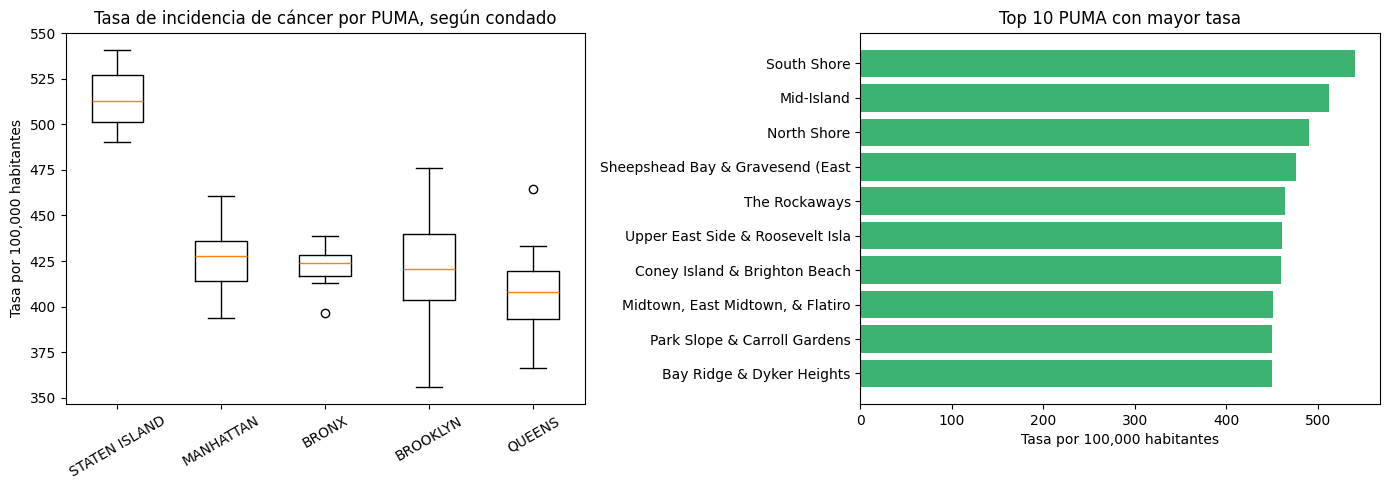

In [36]:
import matplotlib.pyplot as plt

# Tabla: 10 PUMA con mayor tasa
top_cancer = (cancer_base.sort_values("tasa", ascending=False)
              .head(10)[["BORO", "puma", "tasa"]].reset_index(drop=True))
print("Top 10 PUMA por tasa de incidencia de cáncer (por 100,000 habitantes):")
print(top_cancer.to_string(index=False))

# Resumen por condado
resumen_cancer_boro = (cancer_base.groupby("BORO")["tasa"]
    .agg(pumas="count", tasa_prom="mean", tasa_min="min", tasa_max="max")
    .round(1).sort_values("tasa_prom", ascending=False))
print("\nResumen por condado:")
print(resumen_cancer_boro)

# Gráficos: dispersión de tasas por condado (boxplot) y top 10 PUMA
orden = resumen_cancer_boro.index.tolist()
datos = [cancer_base.loc[cancer_base["BORO"] == b, "tasa"] for b in orden]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot(datos)
axes[0].set_xticks(range(1, len(orden) + 1))
axes[0].set_xticklabels(orden, rotation=30)
axes[0].set_title("Tasa de incidencia de cáncer por PUMA, según condado")
axes[0].set_ylabel("Tasa por 100,000 habitantes")

etiquetas = top_cancer["puma"].str.slice(0, 32)
axes[1].barh(etiquetas[::-1], top_cancer["tasa"][::-1], color="mediumseagreen")
axes[1].set_title("Top 10 PUMA con mayor tasa")
axes[1].set_xlabel("Tasa por 100,000 habitantes")
plt.tight_layout()
plt.savefig("fig_cancer_puma_scraping.png", dpi=150)
plt.show()

**Interpretación.** Staten Island tuvo el mayor promedio entre sus áreas PUMA (514,7 casos por 100.000 habitantes). Sus tres áreas ocuparon los primeros lugares del ranking. Fueron South Shore (541,0), Mid-Island (512,7) y North Shore (490,4). Brooklyn mostró el mayor rango entre sus áreas (355,7 a 476,1) y Bronx el menor (396,4 a 438,9)..

*Nota:* según la nota metodológica que publica el propio Registro para sus tablas por vecindario, las tasas están ajustadas por edad y las basadas en pocos casos son inestables. Verificar que el dashboard indique lo mismo antes de citarlo en el informe.

### 8.3 Complemento: cruce de las tasas de cáncer con pobreza, arrestos y colisiones por condado

El dashboard no trae población, así que las tasas de arrestos y colisiones por 100,000 habitantes se mantienen con la población estimada con `PWGTP` (celda de estandarización del numeral 4). Aquí se agrega la tasa de cáncer a nivel de condado (promedio simple de sus PUMA) y se compara con la tasa de pobreza y las tasas de arrestos y colisiones. Son solo cinco puntos (los condados), por lo que el cruce es descriptivo.

         BORO  tasa_cancer_prom  tasa_pobreza_pct  arrestos_x100k  colisiones_x100k
        BRONX             421.7              25.8          2354.5             885.5
     BROOKLYN             421.1              18.3          1687.6            1051.4
    MANHATTAN             427.1              13.8          2064.1             931.9
       QUEENS             405.9              15.8          1290.8             970.3
STATEN ISLAND             514.7              13.8          1101.2             666.4


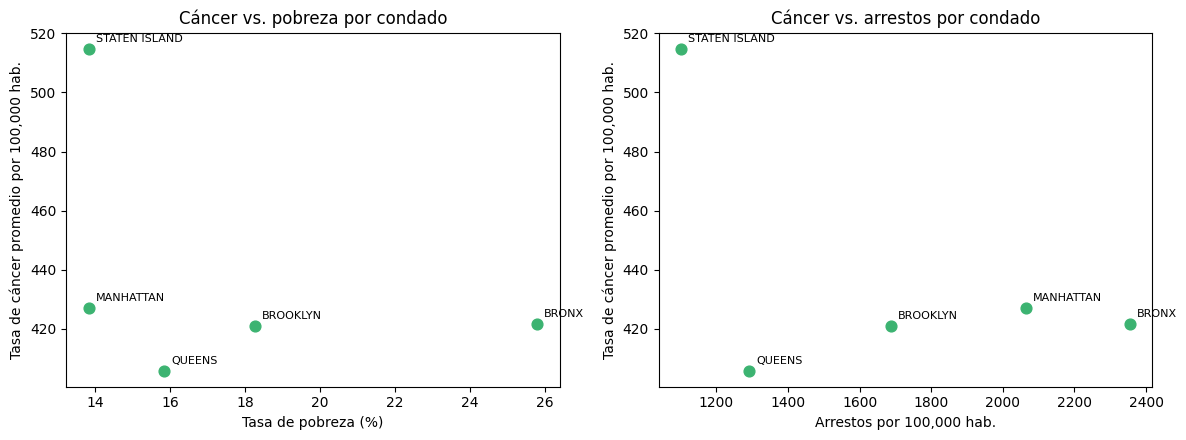

In [37]:
# `pobreza_boro` (cruce pobreza vs. arrestos), `tasas` (estandarización por población) y `mapa_pov` vienen de celdas anteriores
pobreza_boro["BORO"] = pobreza_boro["Boro"].astype(int).map(mapa_pov)

cancer_boro = (cancer_base.groupby("BORO", as_index=False)["tasa"].mean()
               .rename(columns={"tasa": "tasa_cancer_prom"}))

cruce_cancer = (cancer_boro
    .merge(pobreza_boro[["BORO", "tasa_pobreza_pct"]], on="BORO")
    .merge(tasas[["BORO", "arrestos_x100k", "colisiones_x100k"]], on="BORO"))
print(cruce_cancer.round(1).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, xcol, xlabel in [(axes[0], "tasa_pobreza_pct", "Tasa de pobreza (%)"),
                         (axes[1], "arrestos_x100k", "Arrestos por 100,000 hab.")]:
    ax.scatter(cruce_cancer[xcol], cruce_cancer["tasa_cancer_prom"], s=60, color="mediumseagreen")
    for _, f in cruce_cancer.iterrows():
        ax.annotate(f["BORO"], (f[xcol], f["tasa_cancer_prom"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Tasa de cáncer promedio por 100,000 hab.")
axes[0].set_title("Cáncer vs. pobreza por condado")
axes[1].set_title("Cáncer vs. arrestos por condado")
plt.tight_layout()
plt.savefig("fig_cancer_vs_pobreza_arrestos.png", dpi=150)
plt.show()

**Interpretación.** Bronx tuvo la mayor proporción de pobreza (25,8 %) y la mayor tasa de arrestos (2.354,5 por 100.000 habitantes), mientras que su promedio de incidencia de cáncer fue de 421,7 por 100.000. Staten Island tuvo el mayor promedio de incidencia (514,7), la menor tasa de arrestos (1.101,2) y una proporción de pobreza del 13,8 %.

**Limitaciones:** (i) con cinco condados no se puede estimar una correlación inferencial fiable; el cruce es descriptivo y no causal; (ii) la tasa por condado es el promedio simple de sus PUMA, sin ponderar por población, porque el dashboard no publica población por PUMA; (iii) los períodos de referencia difieren (tasas de cáncer del dashboard, pobreza 2018, arrestos y colisiones recientes); (iv) las cifras de cáncer están a nivel de vecindario (PUMA), mientras que los arrestos se registran por precinto policial, por lo que su comparación se realiza de forma agregada por condado.

### 8.4 Incremental 2 — API climática: OpenWeather One Call 3.0 (`day_summary`)

Se descargan las variables diarias para el centro de NYC en las fechas necesarias para cruzar con los datos de siniestros y arrestos. El resultado se guarda en `clima_nyc_diario.csv`; las ejecuciones siguientes solo piden las fechas que falten.

In [38]:
import os, time, requests
import pandas as pd
from datetime import date

LAT, LON = 40.7128, -74.0060                  # centro de NYC (un solo punto para toda la ciudad)
OWM_KEY  = os.environ.get("OPENWEATHER_API_KEY")
LIMITE_OWM = 1000                              # llamadas diarias gratuitas del plan One Call by Call
CACHE_CLIMA = "clima_nyc_diario.csv"
COLS_CLIMA = ["fecha", "temp_min_c", "temp_max_c", "precip_mm", "viento_max_ms", "fuente"]

# --- Fechas necesarias: año de referencia de colisiones + rango de arrestos ---
rng = arr.agg(F.min("fecha").alias("mn"), F.max("fecha").alias("mx")).first()
fechas_necesarias = sorted(
    set(pd.date_range(date(anio_ref, 1, 1), date(anio_ref, 12, 31)).date)
    | set(pd.date_range(rng["mn"], rng["mx"]).date))
print(f"Fechas necesarias: {len(fechas_necesarias)} ({fechas_necesarias[0]} a {fechas_necesarias[-1]})")

# --- Caché local para no repetir llamadas ---
if os.path.exists(CACHE_CLIMA):
    clima_pd = pd.read_csv(CACHE_CLIMA, parse_dates=["fecha"])
    clima_pd["fecha"] = clima_pd["fecha"].dt.date
else:
    clima_pd = pd.DataFrame(columns=COLS_CLIMA)
ya_descargadas = set(clima_pd["fecha"])
faltantes = [f for f in fechas_necesarias if f not in ya_descargadas]
print("Fechas por descargar:", len(faltantes))

def clima_openweather(f):
    # Una llamada por fecha. Los campos se leen con .get para tolerar cambios menores en la respuesta.
    r = requests.get("https://api.openweathermap.org/data/3.0/onecall/day_summary",
                     params={"lat": LAT, "lon": LON, "date": f.isoformat(),
                             "units": "metric", "appid": OWM_KEY}, timeout=30)
    r.raise_for_status()
    j = r.json()
    return {"fecha": f,
            "temp_min_c": j.get("temperature", {}).get("min"),
            "temp_max_c": j.get("temperature", {}).get("max"),
            "precip_mm":  j.get("precipitation", {}).get("total"),
            "viento_max_ms": j.get("wind", {}).get("max", {}).get("speed"),
            "fuente": "OpenWeather One Call 3.0 day_summary"}

def clima_open_meteo(ini, fin):
    # Alternativa sin API key: archivo histórico de Open-Meteo (una sola llamada para todo el rango).
    r = requests.get("https://archive-api.open-meteo.com/v1/archive",
                     params={"latitude": LAT, "longitude": LON,
                             "start_date": ini.isoformat(), "end_date": fin.isoformat(),
                             "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max",
                             "wind_speed_unit": "ms", "timezone": "America/New_York"}, timeout=60)
    r.raise_for_status()
    d = r.json()["daily"]
    return [{"fecha": pd.to_datetime(t).date(),
             "temp_min_c": tmin, "temp_max_c": tmax, "precip_mm": p, "viento_max_ms": v,
             "fuente": "Open-Meteo archive"}
            for t, tmin, tmax, p, v in zip(d["time"], d["temperature_2m_min"], d["temperature_2m_max"],
                                           d["precipitation_sum"], d["wind_speed_10m_max"])]

nuevos = []
if faltantes and OWM_KEY and len(faltantes) <= LIMITE_OWM:
    try:
        for f in faltantes:
            nuevos.append(clima_openweather(f))
            time.sleep(0.05)
    except requests.RequestException as e:
        print("OpenWeather falló, se completa con Open-Meteo:", e)
elif faltantes and OWM_KEY:
    print(f"Se necesitan {len(faltantes)} llamadas (> {LIMITE_OWM}/día). Se usa Open-Meteo.")
elif faltantes:
    print("Sin OPENWEATHER_API_KEY. Se usa Open-Meteo.")

restantes = [f for f in faltantes if f not in {n["fecha"] for n in nuevos}]
if restantes:
    try:
        extra = clima_open_meteo(min(restantes), max(restantes))
        nuevos += [e for e in extra if e["fecha"] in set(restantes)]
    except requests.RequestException as e:
        print("Open-Meteo no disponible:", e)

if nuevos:
    clima_pd = pd.concat([clima_pd, pd.DataFrame(nuevos)], ignore_index=True)
clima_pd = (clima_pd.drop_duplicates("fecha").sort_values("fecha").reset_index(drop=True))
clima_pd.to_csv(CACHE_CLIMA, index=False)

if clima_pd.empty:
    raise RuntimeError("No hay datos climáticos: sin acceso a la API y sin caché local.")
faltan = [f for f in fechas_necesarias if f not in set(clima_pd["fecha"])]
print("Registros climáticos:", len(clima_pd), "| fechas aún sin dato:", len(faltan))
print(clima_pd["fuente"].value_counts())
clima_pd.head()

Fechas necesarias: 546 (2025-01-01 a 2026-06-30)
Fechas por descargar: 546
Sin OPENWEATHER_API_KEY. Se usa Open-Meteo.
Registros climáticos: 546 | fechas aún sin dato: 0
fuente
Open-Meteo archive    546
Name: count, dtype: int64


,fecha,temp_min_c,temp_max_c,precip_mm,viento_max_ms,fuente
0,2025-01-01,3.9,11.0,4.5,6.44,Open-Meteo archive
1,2025-01-02,0.3,5.4,0.0,6.97,Open-Meteo archive
2,2025-01-03,-1.9,3.2,0.0,4.76,Open-Meteo archive
3,2025-01-04,-2.7,-0.1,0.0,7.25,Open-Meteo archive
4,2025-01-05,-3.6,0.4,0.0,5.52,Open-Meteo archive


### 8.5 Resultados de la API: tabla y gráfico del clima extraído

Resumen mensual y serie diaria de temperatura y precipitación, construidos únicamente con los datos extraídos de la API.

Resumen mensual del clima extraído (NYC):
    mes  dias  temp_min_prom_c  temp_max_prom_c  precip_total_mm  dias_con_lluvia  viento_max_ms
2025-01    31             -5.3              1.3             30.3                6            8.3
2025-02    28             -3.2              4.1             79.4               11            8.0
2025-03    31              2.1             12.6            162.5               10            8.5
2025-04    30              7.3             17.1             73.1               10            8.4
2025-05    31             12.7             21.1            201.1               16            7.1
2025-06    30             18.9             28.8             74.9               12            5.8
2025-07    31             22.4             31.8            111.4               15            6.3
2025-08    31             18.4             28.5             23.8                6            6.3
2025-09    30             16.6             25.6            119.5                9    

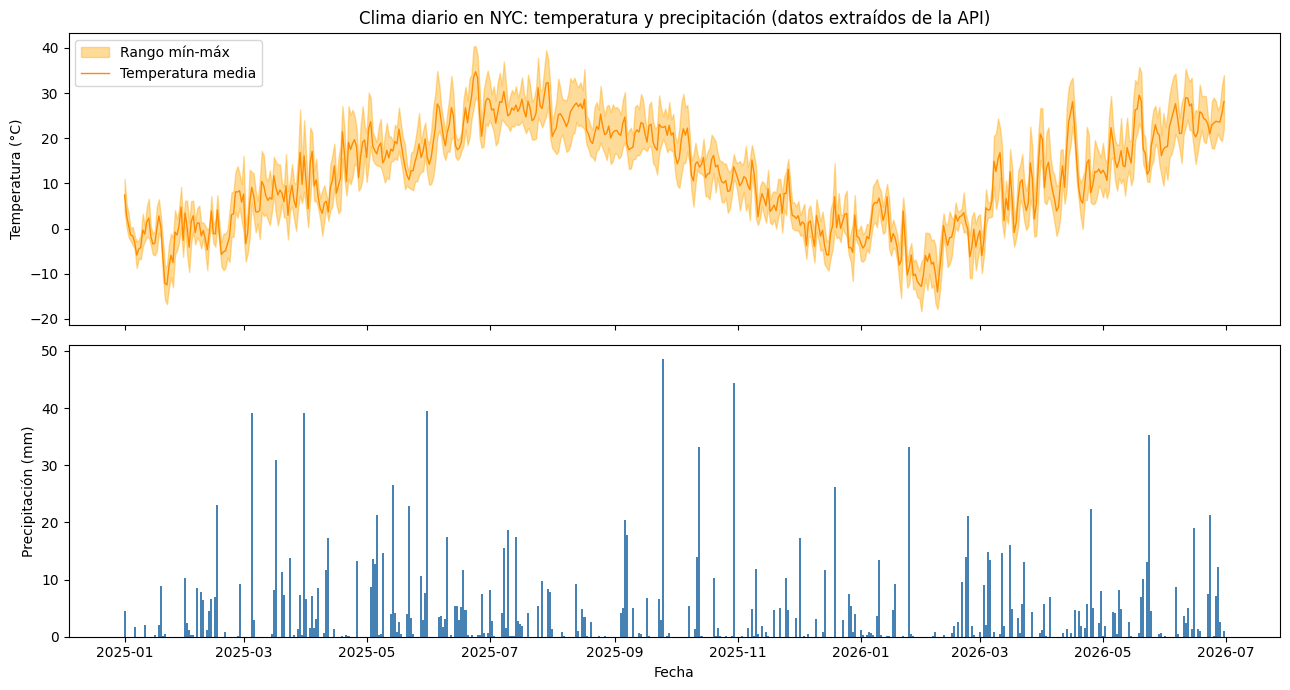

In [39]:
# Tabla: resumen mensual del clima extraído
clima_vis = clima_pd.copy()
clima_vis["fecha"] = pd.to_datetime(clima_vis["fecha"])
clima_vis["mes"] = clima_vis["fecha"].dt.to_period("M").astype(str)
resumen_clima = (clima_vis.groupby("mes")
    .agg(dias=("fecha", "count"),
         temp_min_prom_c=("temp_min_c", "mean"),
         temp_max_prom_c=("temp_max_c", "mean"),
         precip_total_mm=("precip_mm", "sum"),
         dias_con_lluvia=("precip_mm", lambda x: (x >= 1).sum()),
         viento_max_ms=("viento_max_ms", "max"))
    .round(1).reset_index())
print("Resumen mensual del clima extraído (NYC):")
print(resumen_clima.to_string(index=False))

# Gráfico: temperatura diaria (banda mín-máx) y precipitación diaria
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].fill_between(clima_vis["fecha"], clima_vis["temp_min_c"], clima_vis["temp_max_c"],
                     color="orange", alpha=0.4, label="Rango mín-máx")
axes[0].plot(clima_vis["fecha"], (clima_vis["temp_min_c"] + clima_vis["temp_max_c"]) / 2,
             color="darkorange", linewidth=1, label="Temperatura media")
axes[0].set_ylabel("Temperatura (°C)"); axes[0].legend()
axes[0].set_title("Clima diario en NYC: temperatura y precipitación (datos extraídos de la API)")
axes[1].bar(clima_vis["fecha"], clima_vis["precip_mm"], color="steelblue", width=1.0)
axes[1].set_ylabel("Precipitación (mm)"); axes[1].set_xlabel("Fecha")
plt.tight_layout()
plt.savefig("fig_clima_api.png", dpi=150)
plt.show()

**Interpretación.** Las temperaturas aumentaron del invierno al verano y volvieron a bajar en el otoño de 2025. Julio de 2025 tuvo la máxima media diaria más alta (31,8 °C) y febrero de 2026 la mínima media diaria más baja (−7,4 °C). Mayo de 2025 acumuló la mayor precipitación del periodo (201,1 mm), seguido por marzo de 2025 (162,5 mm)..

### 8.6 Complemento: cruce del clima con colisiones y arrestos en Spark

Se agregan colisiones (año de referencia 2025) y arrestos (primer semestre de 2026) por día y se unen de forma distribuida con el DataFrame climático en Spark por fecha para cuantificar la asociación ambiental.

Días con colisiones y clima: 365 | días con arrestos y clima: 181

Correlación de Pearson (colisiones, año 2025 )
            colisiones  heridos  temp_media_c  precip_mm  viento_max_ms
colisiones       1.000    0.797         0.301      0.077         -0.132
heridos          0.797    1.000         0.469      0.051         -0.159

Correlación de Pearson (arrestos, año en curso)
          arrestos  temp_media_c  precip_mm  viento_max_ms
arrestos       1.0         0.134     -0.306          -0.19

Promedio diario de colisiones: día con lluvia vs. día seco
        count   mean
lluvia              
0         246  234.0
1         119  235.1


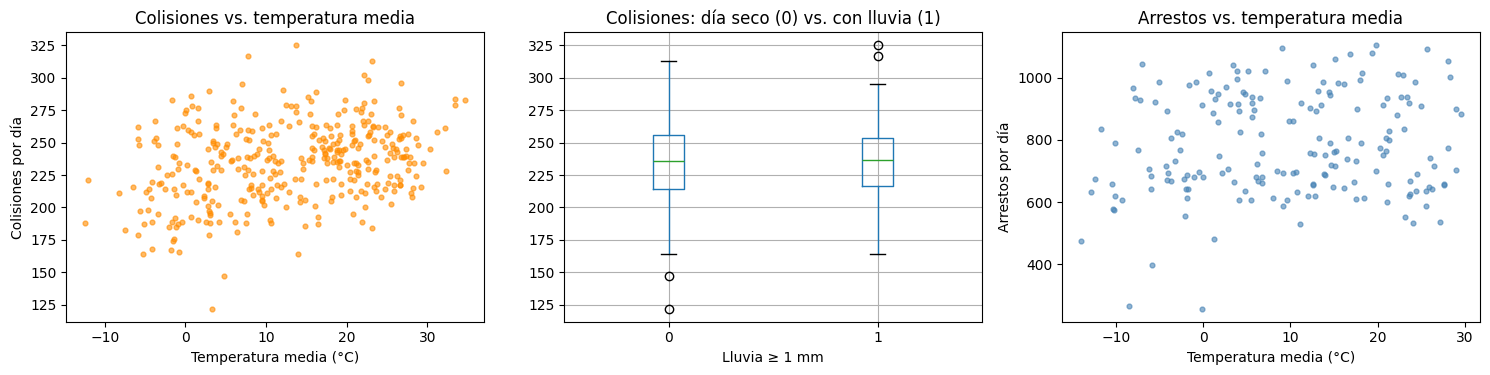

In [40]:
clima_sdf = (spark.createDataFrame(
        clima_pd.assign(fecha=pd.to_datetime(clima_pd["fecha"]).dt.strftime("%Y-%m-%d"))
                .astype({"temp_min_c": float, "temp_max_c": float,
                         "precip_mm": float, "viento_max_ms": float}))
    .withColumn("fecha", F.to_date("fecha"))
    .withColumn("lluvia", (F.col("precip_mm") >= 1).cast("int"))
    .withColumn("temp_media_c", (F.col("temp_min_c") + F.col("temp_max_c")) / 2))

col_dia = (col.filter(F.year("fecha") == anio_ref)
    .groupBy("fecha")
    .agg(F.count("*").alias("colisiones"),
         F.sum(F.col("`NUMBER OF PERSONS INJURED`")).alias("heridos"),
         F.sum(F.col("`NUMBER OF PERSONS KILLED`")).alias("fallecidos")))

arr_dia = arr.groupBy("fecha").count().withColumnRenamed("count", "arrestos")

col_clima = col_dia.join(clima_sdf, "fecha", "inner").toPandas()
arr_clima = arr_dia.join(clima_sdf, "fecha", "inner").toPandas()
print("Días con colisiones y clima:", len(col_clima), "| días con arrestos y clima:", len(arr_clima))

print("\nCorrelación de Pearson (colisiones, año", anio_ref, ")")
print(col_clima[["colisiones", "heridos", "temp_media_c", "precip_mm", "viento_max_ms"]].corr().loc[["colisiones", "heridos"]].round(3))
print("\nCorrelación de Pearson (arrestos, año en curso)")
print(arr_clima[["arrestos", "temp_media_c", "precip_mm", "viento_max_ms"]].corr().loc[["arrestos"]].round(3))

print("\nPromedio diario de colisiones: día con lluvia vs. día seco")
print(col_clima.groupby("lluvia")["colisiones"].agg(["count", "mean"]).round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(col_clima["temp_media_c"], col_clima["colisiones"], s=12, alpha=0.6, color="darkorange")
axes[0].set_title("Colisiones vs. temperatura media")
axes[0].set_xlabel("Temperatura media (°C)"); axes[0].set_ylabel("Colisiones por día")
col_clima.boxplot(column="colisiones", by="lluvia", ax=axes[1])
axes[1].set_title("Colisiones: día seco (0) vs. con lluvia (1)"); axes[1].set_xlabel("Lluvia ≥ 1 mm"); fig.suptitle("")
axes[2].scatter(arr_clima["temp_media_c"], arr_clima["arrestos"], s=12, alpha=0.6, color="steelblue")
axes[2].set_title("Arrestos vs. temperatura media")
axes[2].set_xlabel("Temperatura media (°C)"); axes[2].set_ylabel("Arrestos por día")
plt.tight_layout()
plt.savefig("fig_clima_vs_colisiones_arrestos.png", dpi=150)
plt.show()

**Interpretación.** En 2025, el conteo diario de colisiones registró una correlación positiva moderada con la temperatura media ($r = 0,301$) y aún mayor con el número diario de heridos ($r = 0,469$), debido a la mayor exposición de peatones y ciclistas en meses cálidos, mientras que la correlación con la precipitación acumulada fue baja ($r = 0,077$). El promedio fue de 235,1 colisiones en días con lluvia ($\ge 1$ mm) y de 234,0 en días secos. En el primer semestre de 2026, el conteo diario de arrestos mostró una correlación negativa con la precipitación ($r = -0,306$), reflejando una disminución de detenciones en vía pública durante episodios de lluvia.

**Advertencias:** (i) es una correlación observacional, no causal; (ii) las colisiones se evalúan sobre el año completo 2025 y los arrestos sobre el primer semestre de 2026; (iii) la estación meteorológica representa un punto central de NYC, sin desagregación microclimática por condado.

### 8.7 Fuentes de la sección 8

[11] New York State Department of Health, "New York State Cancer Statistics: Rate by PUMA" (dashboard), New York State Cancer Registry. [Online]. Disponible: https://www.health.ny.gov/statistics/cancer/registry/ratebyPUMA.htm (consultado el 2 de octubre de 2026).

[12] OpenWeather, "One Call API 3.0 – Daily aggregation (`day_summary`)." [Online]. Disponible: https://openweathermap.org/api/one-call-3 (consultado el 2 de octubre de 2026).

[13] Open-Meteo, "Historical Weather API." [Online]. Disponible: https://open-meteo.com/en/docs/historical-weather-api (fuente alternativa sin API key).

---
## 9. Bono de la entrega final (+0.5): modelo de aprendizaje profundo

Se implementa una red neuronal de propagación hacia adelante con **`MultilayerPerceptronClassifier` de Spark MLlib**, que corre sobre el mismo clúster que el resto del proyecto. Se usa para la misma tarea de la pregunta 8 (si una colisión registrada tiene al menos un fallecido), con las mismas variables de entrada, el mismo pipeline de codificación y escalado, la misma partición temporal (2024 entrenamiento, 2025 validación, primer semestre de 2026 prueba) y las mismas métricas. Así la red se compara directamente con la regresión logística.

**Por qué una red profunda.** La regresión logística solo combina las variables de forma lineal. Una red con varias capas ocultas puede aprender interacciones entre hora, ubicación, tipo de vehículo y factor contribuyente (por ejemplo, un tipo de vehículo que solo es riesgoso de noche o en cierta zona) sin definirlas a mano.

**Diseño del experimento.**
- **Desbalance de clases.** El perceptrón de MLlib no acepta pesos por fila (`weightCol`). Para obtener un efecto equivalente a la ponderación usada en la regresión logística, cada colisión fatal del entrenamiento se replica tantas veces como indica ese peso (≈381), lo que deja las dos clases con un tamaño similar. Validación y prueba no se modifican.
- **Arquitecturas probadas.** Dos capas ocultas (32-16 y 64-32) y tres capas ocultas (64-32-16), con activación sigmoide en las ocultas y softmax en la salida, que es la configuración fija de MLlib.
- **Iteraciones.** 50 y 150 iteraciones del optimizador L-BFGS, para observar el efecto de entrenar más tiempo sobre datos replicados.
- **Selección.** La configuración se elige por AUPRC en validación y el umbral por F1 en validación, igual que en la regresión logística. La prueba se usa una sola vez al final.

*Tiempo de ejecución:* las seis configuraciones tardan alrededor de 30 minutos con 2 núcleos; con más núcleos baja proporcionalmente.

Neuronas de entrada: 347 | réplicas por colisión fatal: 381
+-----+-----+
|label|count|
+-----+-----+
|  0.0|83479|
|  1.0|83439|
+-----+-----+

2 capas (32-16) | maxIter=50 | AUPRC val=0.00412
2 capas (32-16) | maxIter=150 | AUPRC val=0.00331
2 capas (64-32) | maxIter=50 | AUPRC val=0.00391
2 capas (64-32) | maxIter=150 | AUPRC val=0.00274
3 capas (64-32-16) | maxIter=50 | AUPRC val=0.00721
3 capas (64-32-16) | maxIter=150 | AUPRC val=0.00346


         arquitectura  maxIter  AUPRC_validacion  AUROC_validacion
0     2 capas (32-16)       50           0.00412           0.61814
1     2 capas (32-16)      150           0.00331           0.56512
2     2 capas (64-32)       50           0.00391           0.62508
3     2 capas (64-32)      150           0.00274           0.58019
4  3 capas (64-32-16)       50           0.00721           0.70516
5  3 capas (64-32-16)      150           0.00346           0.60311

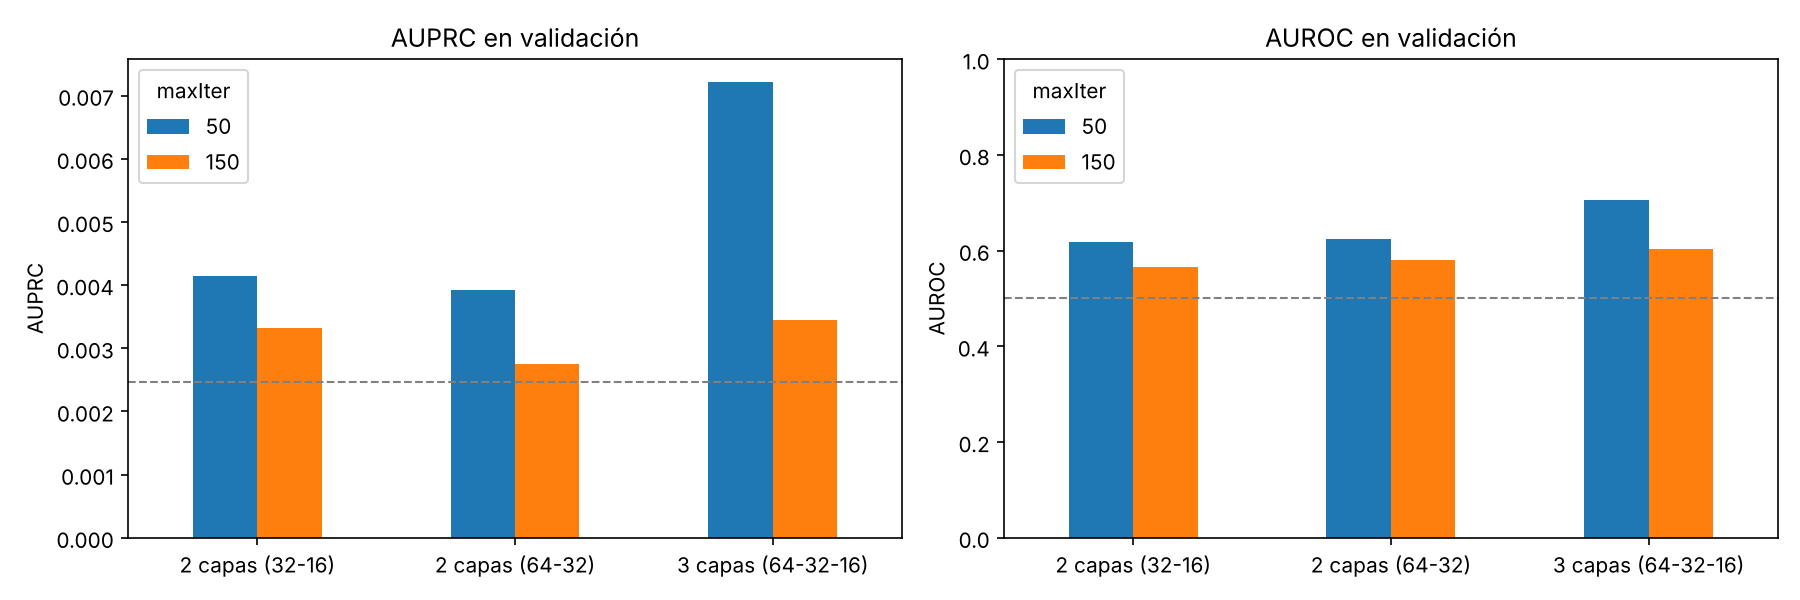

In [41]:
from pyspark.ml.classification import MultilayerPerceptronClassifier

# Réplica de las colisiones fatales con el mismo peso que usó la regresión logística
peso_fatal = train_lr.filter(F.col("label") == 1).first()["peso"]
replicas = int(round(peso_fatal))
train_mlp = (train_lr
    .withColumn("copias", F.when(F.col("label") == 1, replicas).otherwise(1))
    .withColumn("copia", F.explode(F.sequence(F.lit(1), F.col("copias"))))
    .select("label", "features")
    .repartition(4)
    .cache())
n_entradas = train_lr.first()["features"].size
print(f"Neuronas de entrada: {n_entradas} | réplicas por colisión fatal: {replicas}")
train_mlp.groupBy("label").count().orderBy("label").show()

arquitecturas = {
    "2 capas (32-16)": [32, 16],
    "2 capas (64-32)": [64, 32],
    "3 capas (64-32-16)": [64, 32, 16],
}
corridas_mlp = []
for nombre, ocultas in arquitecturas.items():
    for iteraciones in [50, 150]:
        red = MultilayerPerceptronClassifier(layers=[n_entradas, *ocultas, 2], maxIter=iteraciones,
                                             blockSize=256, seed=42).fit(train_mlp)
        pred_val = red.transform(val_lr)
        corridas_mlp.append(dict(arquitectura=nombre, maxIter=iteraciones,
                                 AUPRC_validacion=auprc.evaluate(pred_val),
                                 AUROC_validacion=aucroc.evaluate(pred_val), modelo=red))
        print(f"{nombre} | maxIter={iteraciones} | AUPRC val={corridas_mlp[-1]['AUPRC_validacion']:.5f}")

tabla_mlp = pd.DataFrame(corridas_mlp).drop(columns="modelo")
display(tabla_mlp.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica, titulo in zip(axes, ["AUPRC_validacion", "AUROC_validacion"],
                               ["AUPRC en validación", "AUROC en validación"]):
    tabla_mlp.pivot(index="arquitectura", columns="maxIter", values=metrica).plot.bar(ax=ax, rot=0)
    ax.set(title=titulo, xlabel="", ylabel=metrica.split("_")[0])
axes[0].axhline(val_lr.agg(F.avg("label")).first()[0], color="grey", ls="--", lw=1)
axes[1].axhline(.5, color="grey", ls="--", lw=1)
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.legend(title="maxIter", loc="upper left")
plt.tight_layout()
plt.savefig("fig_mlp_validacion.png", dpi=150)
plt.show()

Configuración elegida: 3 capas (64-32-16) | maxIter=50
Proporción fatal en prueba: 0.0025


                modelo  umbral   AUPRC   AUROC  VP     FP  FN  precision  recall      F1
0  Regresión logística    0.55  0.0042  0.5397  50  16382  52     0.0030  0.4902  0.0060
1   Red neuronal (MLP)    0.85  0.0044  0.6020  23   5934  79     0.0039  0.2255  0.0076

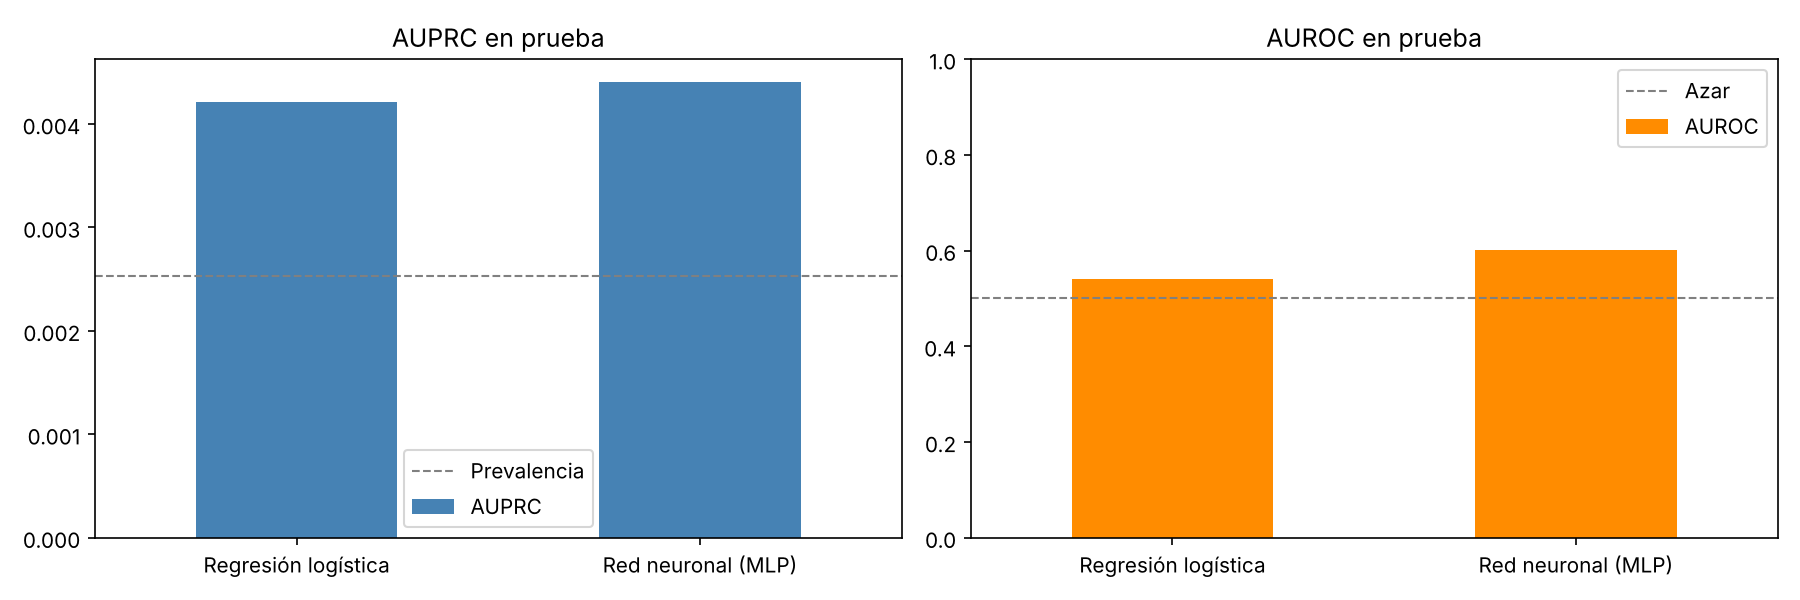

In [42]:
mejor_corrida = max(corridas_mlp, key=lambda c: c["AUPRC_validacion"])
mejor_mlp = mejor_corrida["modelo"]
print(f"Configuración elegida: {mejor_corrida['arquitectura']} | maxIter={mejor_corrida['maxIter']}")

rendimiento_val_mlp = evaluar_umbrales(mejor_mlp.transform(val_lr), [.10, .25, .40, .55, .70, .85, .95])
display(rendimiento_val_mlp.round(4))
umbral_mlp = float(rendimiento_val_mlp.sort_values(["F1", "recall"], ascending=False).iloc[0]["umbral"])
pred_prueba_mlp = mejor_mlp.transform(test_lr)

# Comparación en prueba con la regresión logística de la pregunta 8
filas = []
for modelo, pred, umbral in [("Regresión logística", pred_prueba, float(umbral_elegido)),
                             ("Red neuronal (MLP)", pred_prueba_mlp, umbral_mlp)]:
    fila = evaluar_umbrales(pred, [umbral]).iloc[0].to_dict()
    fila.update(modelo=modelo, AUPRC=auprc.evaluate(pred), AUROC=aucroc.evaluate(pred))
    filas.append(fila)
comparacion = pd.DataFrame(filas)[["modelo", "umbral", "AUPRC", "AUROC", "VP", "FP", "FN",
                                   "precision", "recall", "F1"]]
prevalencia_prueba = test_lr.agg(F.avg("label")).first()[0]
print(f"Proporción fatal en prueba: {prevalencia_prueba:.4f}")
display(comparacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparacion.set_index("modelo")[["AUPRC"]].plot.bar(ax=axes[0], rot=0, legend=False, color=["steelblue"])
axes[0].axhline(prevalencia_prueba, color="grey", ls="--", lw=1, label="Prevalencia")
axes[0].set(title="AUPRC en prueba", xlabel="")
axes[0].legend()
comparacion.set_index("modelo")[["AUROC"]].plot.bar(ax=axes[1], rot=0, legend=False, color=["darkorange"])
axes[1].axhline(.5, color="grey", ls="--", lw=1, label="Azar")
axes[1].set(title="AUROC en prueba", xlabel="", ylim=(0, 1))
axes[1].legend()
plt.tight_layout()
plt.savefig("fig_mlp_vs_logistica.png", dpi=150)
plt.show()

#### Interpretación de la red neuronal

En validación, la red de tres capas ocultas (64-32-16) con 50 iteraciones obtuvo la mayor AUPRC (0,00721) y la mayor AUROC (0,705). En las tres arquitecturas, pasar de 50 a 150 iteraciones empeoró las dos métricas: con las colisiones fatales replicadas, entrenar más tiempo hace que la red memorice esos pocos casos y generalice peor. El umbral de 0,85 se eligió por F1 en validación.

En la prueba temporal (primer semestre de 2026), la red obtuvo una AUROC de 0,602 frente a 0,540 de la regresión logística, y una AUPRC de 0,0044 frente a 0,0042, con una prevalencia de 0,0025. Con su umbral, la red identificó 23 de las 102 colisiones fatales (exhaustividad del 22,5 %) con 5.934 falsos positivos; la regresión logística detectó 50 con 16.382 falsos positivos. La precisión de la red fue del 0,39 % frente al 0,30 %, y el F1 de 0,0076 frente a 0,0060.

La red ordena mejor las colisiones por riesgo que el modelo lineal, lo que indica que hay interacciones entre las variables que la regresión logística no captura. Aun así, la mejora es moderada: la AUROC bajó de 0,705 en validación a 0,602 en prueba y la AUPRC sigue cerca de la prevalencia. Con 219 colisiones fatales en el entrenamiento y solo hora, ubicación, tipo de vehículo y factor contribuyente como entradas, ninguno de los dos modelos sirve para predecir colisiones fatales de forma operativa. Variables como velocidad, tipo de vía o condiciones de iluminación podrían mejorar el desempeño.

---
## Cierre de la sesión de Spark

In [43]:
# Ejecutar solo al finalizar todo el trabajo del notebook
# spark.stop()